# Training, early stopping and policy comparison
All nine first-phase and twelve advanced fits are actual cloud runs. The fixed validation split alone determines selection.

In [1]:
import hashlib, json, math, os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code
EMBEDDED = json.loads('{"global": {"raw": "{\\n  \\"selected\\": \\"frozen_clip\\",\\n  \\"selected_validation\\": {\\n    \\"queries\\": 3132,\\n    \\"candidate_moments\\": 15927,\\n    \\"corpus_consensus_r1_iou50\\": 0.05779054916985951,\\n    \\"corpus_consensus_r5_iou50\\": 0.11143039591315454,\\n    \\"corpus_video_r1\\": 0.14367816091954022,\\n    \\"corpus_video_r5\\": 0.19029374201787994,\\n    \\"within_video_official_rank1\\": 0.1334610472541507,\\n    \\"within_video_official_rank5\\": 0.3847381864623244,\\n    \\"within_video_official_miou\\": 0.36704448701575143,\\n    \\"consensus_attainable_fraction\\": 1.0,\\n    \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n    \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n  },\\n  \\"baseline\\": {\\n    \\"queries\\": 3132,\\n    \\"candidate_moments\\": 15927,\\n    \\"corpus_consensus_r1_iou50\\": 0.05779054916985951,\\n    \\"corpus_consensus_r5_iou50\\": 0.11143039591315454,\\n    \\"corpus_video_r1\\": 0.14367816091954022,\\n    \\"corpus_video_r5\\": 0.19029374201787994,\\n    \\"within_video_official_rank1\\": 0.1334610472541507,\\n    \\"within_video_official_rank5\\": 0.3847381864623244,\\n    \\"within_video_official_miou\\": 0.36704448701575143,\\n    \\"consensus_attainable_fraction\\": 1.0,\\n    \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n    \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n  },\\n  \\"phases\\": [\\n    {\\n      \\"phase\\": \\"phase1\\",\\n      \\"report_sha256\\": \\"671ca0adab08434de2a3ea618e54ba427c8d8a19cd180c5ad3757409d30e7688\\",\\n      \\"checkpoint_sha256\\": \\"97a54a16c7df3110ec051887a9a711a0217514e558055209d4c26cfc742b35d6\\",\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05779054916985951,\\n        \\"corpus_consensus_r5_iou50\\": 0.11143039591315454,\\n        \\"corpus_video_r1\\": 0.14367816091954022,\\n        \\"corpus_video_r5\\": 0.19029374201787994,\\n        \\"within_video_official_rank1\\": 0.1334610472541507,\\n        \\"within_video_official_rank5\\": 0.3847381864623244,\\n        \\"within_video_official_miou\\": 0.36704448701575143,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"phase\\": \\"phase2\\",\\n      \\"report_sha256\\": \\"49a03fb7b212a61c4ad7a2c8ca745f37490723333f1680169ce7ee9eb7c9dfe4\\",\\n      \\"checkpoint_sha256\\": \\"97a54a16c7df3110ec051887a9a711a0217514e558055209d4c26cfc742b35d6\\",\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05779054916985951,\\n        \\"corpus_consensus_r5_iou50\\": 0.11143039591315454,\\n        \\"corpus_video_r1\\": 0.14367816091954022,\\n        \\"corpus_video_r5\\": 0.19029374201787994,\\n        \\"within_video_official_rank1\\": 0.1334610472541507,\\n        \\"within_video_official_rank5\\": 0.3847381864623244,\\n        \\"within_video_official_miou\\": 0.36704448701575143,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    }\\n  ],\\n  \\"protocol_sha256\\": \\"d81c9ef5aa881b04440806702312023135aea8eab9b6a4ba9c10fcab335a39a3\\",\\n  \\"cache_manifest_sha256\\": \\"ea73dced79e83cfc735652d6f8e702011d4e663c3fd9307ef010f66b9120a785\\",\\n  \\"selected_checkpoint_sha256\\": \\"79dbec526ac9aa5900d6c42ad8c33dee870e89425cac08be4f2075a94fccfdbb\\",\\n  \\"checkpoint_replay_max_abs_error\\": 0.0,\\n  \\"test_targets_used\\": false\\n}", "sha256": "90fbdf14abf83c339aed47f040aecf52ab2d52b8db883067abf255fce17eb5c7"}, "heldout": {"raw": "{\\n  \\"schema\\": 1,\\n  \\"source_manifest_sha256\\": \\"ad99d633cee842d81a237dcd95e75f39edcf1589392963a3f5310fbf0cbda09b\\",\\n  \\"cache_manifest_sha256\\": \\"ea73dced79e83cfc735652d6f8e702011d4e663c3fd9307ef010f66b9120a785\\",\\n  \\"selected_checkpoint_sha256\\": \\"79dbec526ac9aa5900d6c42ad8c33dee870e89425cac08be4f2075a94fccfdbb\\",\\n  \\"official_test_sha256\\": \\"1891c04ec48b3d364c739594b2b6413806b74bd9027c092d896e7ebb930ff1cd\\",\\n  \\"winner\\": \\"frozen_clip\\",\\n  \\"adapted_score_weight\\": 0.0,\\n  \\"test_cohort_sha256\\": \\"6e4dcdfe816138cae7803db0977d9b9300a3593cd0d49167b64b2b270d49be38\\",\\n  \\"expected_test_queries\\": 2972,\\n  \\"expected_query_ids_sha256\\": \\"756b9284331409d16790d03ef2559333c0fd036b3e9f95d99b7050186315f06c\\",\\n  \\"global_protocol_sha256\\": \\"d81c9ef5aa881b04440806702312023135aea8eab9b6a4ba9c10fcab335a39a3\\",\\n  \\"policy_sha256\\": \\"8f16e99d6207d7c013ea69ef3ed601471d2cad4a23f168829f9109950003ad16\\",\\n  \\"baseline\\": {\\n    \\"queries\\": 2972,\\n    \\"candidate_moments\\": 15039,\\n    \\"corpus_consensus_r1_iou50\\": 0.06493943472409153,\\n    \\"corpus_consensus_r5_iou50\\": 0.12954239569313594,\\n    \\"corpus_video_r1\\": 0.1692462987886945,\\n    \\"corpus_video_r5\\": 0.21635262449528936,\\n    \\"within_video_official_rank1\\": 0.1271870794078062,\\n    \\"within_video_official_rank5\\": 0.3495962314939435,\\n    \\"within_video_official_miou\\": 0.35831277104830267,\\n    \\"consensus_attainable_fraction\\": 1.0,\\n    \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n    \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n  },\\n  \\"selected\\": {\\n    \\"queries\\": 2972,\\n    \\"candidate_moments\\": 15039,\\n    \\"corpus_consensus_r1_iou50\\": 0.06493943472409153,\\n    \\"corpus_consensus_r5_iou50\\": 0.12954239569313594,\\n    \\"corpus_video_r1\\": 0.1692462987886945,\\n    \\"corpus_video_r5\\": 0.21635262449528936,\\n    \\"within_video_official_rank1\\": 0.1271870794078062,\\n    \\"within_video_official_rank5\\": 0.3495962314939435,\\n    \\"within_video_official_miou\\": 0.35831277104830267,\\n    \\"consensus_attainable_fraction\\": 1.0,\\n    \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n    \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n  },\\n  \\"encoder\\": {\\n    \\"model_id\\": \\"openai/clip-vit-base-patch32\\",\\n    \\"revision\\": \\"3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268\\",\\n    \\"weights_sha256\\": \\"a63082132ba4f97a80bea76823f544493bffa8082296d62d71581a4feff1576f\\",\\n    \\"loading_info\\": {\\n      \\"missing_keys\\": [],\\n      \\"unexpected_keys\\": [],\\n      \\"mismatched_keys\\": [],\\n      \\"error_msgs\\": []\\n    }\\n  },\\n  \\"test_labels_used_only_after_global_freeze\\": true,\\n  \\"limits\\": [\\n    \\"Available licensed subset, not the full benchmark.\\",\\n    \\"One-shot consistency guard is not adversarial authentication.\\",\\n    \\"Unknown pretrained exposure; repeated validation selection.\\"\\n  ],\\n  \\"rank_evidence\\": {\\n    \\"manifest_sha256\\": \\"f79207a919c793984e7f97340db38d1ae12fdf40aefffff9e04de821ed5f1075\\",\\n    \\"directory\\": \\"video-final-test-rank-evidence\\",\\n    \\"queries\\": 2972,\\n    \\"videos\\": 741,\\n    \\"independent_saved_rank_replay\\": true\\n  }\\n}", "sha256": "bfe324fd12fe6631e4d1a5804a8dfe64ae904f3cce904d85825eb04498b8206a"}, "phase1": {"raw": "{\\n  \\"baseline\\": {\\n    \\"queries\\": 3132,\\n    \\"candidate_moments\\": 15927,\\n    \\"corpus_consensus_r1_iou50\\": 0.05779054916985951,\\n    \\"corpus_consensus_r5_iou50\\": 0.11143039591315454,\\n    \\"corpus_video_r1\\": 0.14367816091954022,\\n    \\"corpus_video_r5\\": 0.19029374201787994,\\n    \\"within_video_official_rank1\\": 0.1334610472541507,\\n    \\"within_video_official_rank5\\": 0.3847381864623244,\\n    \\"within_video_official_miou\\": 0.36704448701575143,\\n    \\"consensus_attainable_fraction\\": 1.0,\\n    \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n    \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n  },\\n  \\"runs\\": [\\n    {\\n      \\"config\\": {\\n        \\"name\\": \\"lr001\\",\\n        \\"lr\\": 0.001,\\n        \\"weight_decay\\": 0.01\\n      },\\n      \\"seeds\\": [\\n        {\\n          \\"seed\\": 42,\\n          \\"best_epoch\\": 1,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 8.940107011988228,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 8.575005053117474,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 8.45560620589643,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.038314174860715866\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 8.384189332541634,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04278416186571121\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 8.332671925668295,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04150702431797981\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 8.293981546616207,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 8.263146223132852,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 8.235730074035866,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04118774086236954\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 8.21399185659762,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.03991059958934784\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 1337,\\n          \\"best_epoch\\": 2,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 8.933833889895066,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 8.56819200265018,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04597701132297516\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 8.449400676713813,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04342273250222206\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 8.378259086658211,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.039591316133737564\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 8.328030932248641,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.044380586594343185\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 8.290862360716627,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04533844068646431\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 8.26136768210521,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 8.235007982522843,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04565772786736488\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 8.213860347120734,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04150702431797981\\n            },\\n            {\\n              \\"epoch\\": 10,\\n              \\"train_loss\\": 8.194092076951579,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04022988677024841\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 2026,\\n          \\"best_epoch\\": 2,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 8.92681895715493,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04150702431797981\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 8.565353918194761,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 8.449484705688645,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04246487841010094\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 8.382156969791712,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 8.333981035619077,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04342273250222206\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 8.294647638268147,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 8.264466615270289,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043742019683122635\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 8.23693662729256,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04342273250222206\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 8.215640781275333,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.040868453681468964\\n            },\\n            {\\n              \\"epoch\\": 10,\\n              \\"train_loss\\": 8.196684235180774,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.03927202895283699\\n            }\\n          ]\\n        }\\n      ],\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.04661558109833972,\\n        \\"corpus_consensus_r5_iou50\\": 0.11206896551724138,\\n        \\"corpus_video_r1\\": 0.13825031928480205,\\n        \\"corpus_video_r5\\": 0.19763729246487868,\\n        \\"within_video_official_rank1\\": 0.17305236270753513,\\n        \\"within_video_official_rank5\\": 0.4763729246487867,\\n        \\"within_video_official_miou\\": 0.3430449127288208,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"config\\": {\\n        \\"name\\": \\"lr0003\\",\\n        \\"lr\\": 0.0003,\\n        \\"weight_decay\\": 0.01\\n      },\\n      \\"seeds\\": [\\n        {\\n          \\"seed\\": 42,\\n          \\"best_epoch\\": 1,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 9.205807565419944,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04789271950721741\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 8.83089013054868,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04757343605160713\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 8.716082386657725,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04150702431797981\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 8.633115214362718,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04214559495449066\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 8.567976809793398,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.03927202895283699\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 8.517069892465694,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 8.476454839204141,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04278416186571121\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 8.442742268141668,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04118774086236954\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 8.414882231124485,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04469987377524376\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 1337,\\n          \\"best_epoch\\": 2,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 9.199794441284306,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04725414887070656\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 8.824009314619994,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04821200668811798\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 8.708516802482384,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 8.627395223373073,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04342273250222206\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 8.564509445958565,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 8.51550113676992,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 8.476603779111707,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04214559495449066\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 8.442944332172456,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04693486541509628\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 8.415782525985161,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04469987377524376\\n            },\\n            {\\n              \\"epoch\\": 10,\\n              \\"train_loss\\": 8.391419476100612,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 2026,\\n          \\"best_epoch\\": 2,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 9.193097340630084,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04661558195948601\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 8.822057476969343,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04821200668811798\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 8.705975832173397,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 8.624273971960099,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04150702431797981\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 8.564786959430204,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 8.51748991592127,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04022988677024841\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 8.479024759747531,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 8.446141348862565,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04661558195948601\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 8.419900215963754,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04278416186571121\\n            },\\n            {\\n              \\"epoch\\": 10,\\n              \\"train_loss\\": 8.396878756774765,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            }\\n          ]\\n        }\\n      ],\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.04693486590038314,\\n        \\"corpus_consensus_r5_iou50\\": 0.11206896551724138,\\n        \\"corpus_video_r1\\": 0.13952745849297574,\\n        \\"corpus_video_r5\\": 0.19859514687100893,\\n        \\"within_video_official_rank1\\": 0.17656449553001277,\\n        \\"within_video_official_rank5\\": 0.4846743295019157,\\n        \\"within_video_official_miou\\": 0.34720093656875267,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"config\\": {\\n        \\"name\\": \\"decay01\\",\\n        \\"lr\\": 0.001,\\n        \\"weight_decay\\": 0.1\\n      },\\n      \\"seeds\\": [\\n        {\\n          \\"seed\\": 42,\\n          \\"best_epoch\\": 13,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 8.941701496421196,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 8.579726333443887,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04214559495449066\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 8.462662808474422,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.038952745497226715\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 8.393515508017266,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 8.3441966954269,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04150702431797981\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 8.307680220349514,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04342273250222206\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 8.278765565947658,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 8.25332645851624,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 8.233244661400724,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 10,\\n              \\"train_loss\\": 8.216739523257688,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 11,\\n              \\"train_loss\\": 8.20163460927075,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04469987377524376\\n            },\\n            {\\n              \\"epoch\\": 12,\\n              \\"train_loss\\": 8.187047915996718,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            },\\n            {\\n              \\"epoch\\": 13,\\n              \\"train_loss\\": 8.177107032645663,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04565772786736488\\n            },\\n            {\\n              \\"epoch\\": 14,\\n              \\"train_loss\\": 8.167818036082284,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04118774086236954\\n            },\\n            {\\n              \\"epoch\\": 15,\\n              \\"train_loss\\": 8.160075008226935,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04278416186571121\\n            },\\n            {\\n              \\"epoch\\": 16,\\n              \\"train_loss\\": 8.152794122675372,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 17,\\n              \\"train_loss\\": 8.146127856216516,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 18,\\n              \\"train_loss\\": 8.141191393925643,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.040868453681468964\\n            },\\n            {\\n              \\"epoch\\": 19,\\n              \\"train_loss\\": 8.136302276085537,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04214559495449066\\n            },\\n            {\\n              \\"epoch\\": 20,\\n              \\"train_loss\\": 8.131919162991272,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 21,\\n              \\"train_loss\\": 8.128218287754116,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04054917022585869\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 1337,\\n          \\"best_epoch\\": 7,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 8.935469764829165,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04278416186571121\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 8.573047177995672,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04565772786736488\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 8.45683137413428,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04278416186571121\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 8.387996089097786,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.03991059958934784\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 8.339749495887148,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 8.304679698630064,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04533844068646431\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 8.277291603226486,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04789271950721741\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 8.252855381301,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04725414887070656\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 8.233410796793605,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04597701132297516\\n            },\\n            {\\n              \\"epoch\\": 10,\\n              \\"train_loss\\": 8.215035838635252,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 11,\\n              \\"train_loss\\": 8.201166676196669,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04565772786736488\\n            },\\n            {\\n              \\"epoch\\": 12,\\n              \\"train_loss\\": 8.188721781917177,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            },\\n            {\\n              \\"epoch\\": 13,\\n              \\"train_loss\\": 8.17853401508961,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04246487841010094\\n            },\\n            {\\n              \\"epoch\\": 14,\\n              \\"train_loss\\": 8.170046265418545,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04022988677024841\\n            },\\n            {\\n              \\"epoch\\": 15,\\n              \\"train_loss\\": 8.160978281994275,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04214559495449066\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 2026,\\n          \\"best_epoch\\": 12,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 8.928499836211019,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04150702431797981\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 8.570093978695722,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04533844068646431\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 8.456664356093254,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04214559495449066\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 8.391749372072091,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04246487841010094\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 8.345831421940154,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 8.308602305529766,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04565772786736488\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 8.28035994597873,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04565772786736488\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 8.254652683924585,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 8.235068363235404,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04533844068646431\\n            },\\n            {\\n              \\"epoch\\": 10,\\n              \\"train_loss\\": 8.217513691504529,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04150702431797981\\n            },\\n            {\\n              \\"epoch\\": 11,\\n              \\"train_loss\\": 8.203977406040346,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 12,\\n              \\"train_loss\\": 8.191026443798432,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04789271950721741\\n            },\\n            {\\n              \\"epoch\\": 13,\\n              \\"train_loss\\": 8.179974227884228,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 14,\\n              \\"train_loss\\": 8.169811962822493,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 15,\\n              \\"train_loss\\": 8.16176923707933,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 16,\\n              \\"train_loss\\": 8.154409197545979,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.044380586594343185\\n            },\\n            {\\n              \\"epoch\\": 17,\\n              \\"train_loss\\": 8.147833442392045,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 18,\\n              \\"train_loss\\": 8.142501094528091,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.03991059958934784\\n            },\\n            {\\n              \\"epoch\\": 19,\\n              \\"train_loss\\": 8.137881050376212,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04118774086236954\\n            },\\n            {\\n              \\"epoch\\": 20,\\n              \\"train_loss\\": 8.132972516701988,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04565772786736488\\n            }\\n          ]\\n        }\\n      ],\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.04565772669220945,\\n        \\"corpus_consensus_r5_iou50\\": 0.10919540229885058,\\n        \\"corpus_video_r1\\": 0.14687100893997446,\\n        \\"corpus_video_r5\\": 0.20274584929757344,\\n        \\"within_video_official_rank1\\": 0.17113665389527458,\\n        \\"within_video_official_rank5\\": 0.46839080459770116,\\n        \\"within_video_official_miou\\": 0.3357598978288634,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    }\\n  ],\\n  \\"selected\\": \\"frozen_clip\\",\\n  \\"selected_validation\\": {\\n    \\"queries\\": 3132,\\n    \\"candidate_moments\\": 15927,\\n    \\"corpus_consensus_r1_iou50\\": 0.05779054916985951,\\n    \\"corpus_consensus_r5_iou50\\": 0.11143039591315454,\\n    \\"corpus_video_r1\\": 0.14367816091954022,\\n    \\"corpus_video_r5\\": 0.19029374201787994,\\n    \\"within_video_official_rank1\\": 0.1334610472541507,\\n    \\"within_video_official_rank5\\": 0.3847381864623244,\\n    \\"within_video_official_miou\\": 0.36704448701575143,\\n    \\"consensus_attainable_fraction\\": 1.0,\\n    \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n    \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n  },\\n  \\"protocol_sha256\\": \\"d81c9ef5aa881b04440806702312023135aea8eab9b6a4ba9c10fcab335a39a3\\",\\n  \\"cache_manifest_sha256\\": \\"ea73dced79e83cfc735652d6f8e702011d4e663c3fd9307ef010f66b9120a785\\",\\n  \\"selected_checkpoint_sha256\\": \\"97a54a16c7df3110ec051887a9a711a0217514e558055209d4c26cfc742b35d6\\",\\n  \\"checkpoint_replay_max_abs_error\\": 0.0,\\n  \\"test_targets_used\\": false,\\n  \\"service_seconds\\": 13233.970929493,\\n  \\"completed_fits\\": 9,\\n  \\"required_fits\\": 9,\\n  \\"continuation_identity\\": {\\n    \\"schema\\": 2,\\n    \\"origin_identity_sha256\\": \\"8132f0004b232f7a6e305767dd84546c29cd956781cd58902291278868867ee2\\",\\n    \\"portable_policy_sha256\\": \\"76481000952884b49203be09ed8867f97ea0d2851a438100efd019c0be64f916\\",\\n    \\"lineage_sha256\\": \\"4eb1a1df69f72dcfc4a92c7932e2cf861ee996e6348c4411b0f563bcb17fbae4\\",\\n    \\"actual_runtime_sha256\\": \\"a42f9db0b44c2378182ec8a286e0d0a477864c19ba41fd1cad4277da7b9838e4\\"\\n  },\\n  \\"origin_identity\\": {\\n    \\"schema\\": 1,\\n    \\"phase\\": \\"phase1\\",\\n    \\"protocol_sha256\\": \\"d81c9ef5aa881b04440806702312023135aea8eab9b6a4ba9c10fcab335a39a3\\",\\n    \\"cache_manifest_sha256\\": \\"ea73dced79e83cfc735652d6f8e702011d4e663c3fd9307ef010f66b9120a785\\",\\n    \\"implementation_sha256\\": {\\n      \\"models/resumable_training.py\\": \\"fb8fec504c3e4e3a0035613b106d96519d385f9ea5d32e78043aa76a6be2614d\\",\\n      \\"config.py\\": \\"b132152b04376cf37042eaa9f899cc365a03398933ead1af25517d244e961ef4\\",\\n      \\"data/didemo.py\\": \\"3f23a900b4809f483e7b47c1011481dd37f8f06bf9d8d01817ad96cfff4ec358\\",\\n      \\"models/moment_encoder.py\\": \\"5f50dd10fb97f3cfa88afc21d1b87f3c06c80e001f9d280bdcd31932840092ba\\",\\n      \\"models/research_followup.py\\": \\"0af9e2ab7382347503466990733222d2143e63a8111920f7910366a2e4384951\\",\\n      \\"models/localization_followup.py\\": \\"b93cf87f7a88f203dab45e8b7fd5cacefc58a799526e08f6976b7f2b4712002a\\",\\n      \\"models/moment_training.py\\": \\"e9de30757223951640e13479d2b0c16f7719b51359707d21e7123bb8b89ff2d3\\",\\n      \\"models/positive_index.py\\": \\"6726bf15bfb973847b3f284df7fb2e90fb0751132dfd59043a321ec3518d3da4\\",\\n      \\"models/encoding_progress.py\\": \\"131c30b0e445e387174e234a8690551f3f880cb64bda5e616d072a08fe083e50\\",\\n      \\"models/moments.py\\": \\"a94727b0acf118449968f20676d0a018c573c3fc7afabcd165708399d956bd88\\",\\n      \\"models/encoder.py\\": \\"8e90964e272b72fecc75b60271c6f5ec0cbab71ccdb9da9cbf5c206ab78fc9d1\\",\\n      \\"data/decoder_preflight.py\\": \\"22df37f1e052f2c3127d7d2c1518c8804aa2ab0682c6a7f8953331c4b35c8acc\\",\\n      \\"data/decoder_recovery.py\\": \\"d86c281b93a493fea8230b6b3b3271488a73a470eb1bcef07c491db6c3fc9565\\",\\n      \\"data/prepare_moments.py\\": \\"944121890873fb83368de1c7b79e319c4b4d7f53b08e9954ff950acfcf9bae9e\\",\\n      \\"data/research_receipts.py\\": \\"2664029bd3a66997d2d0e54015260893d9197927d75fe653313d634fba1e0917\\"\\n    },\\n    \\"coverage\\": {\\n      \\"candidate_count\\": 7592,\\n      \\"retained_media\\": 7454,\\n      \\"decoder_sources\\": 7464,\\n      \\"decoder_excluded\\": 10\\n    },\\n    \\"encoding_identity\\": {\\n      \\"source_manifest_sha256\\": \\"ad99d633cee842d81a237dcd95e75f39edcf1589392963a3f5310fbf0cbda09b\\",\\n      \\"encoder\\": {\\n        \\"model_id\\": \\"openai/clip-vit-base-patch32\\",\\n        \\"revision\\": \\"3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268\\",\\n        \\"weights_sha256\\": \\"a63082132ba4f97a80bea76823f544493bffa8082296d62d71581a4feff1576f\\",\\n        \\"loading_info\\": {\\n          \\"missing_keys\\": [],\\n          \\"unexpected_keys\\": [],\\n          \\"mismatched_keys\\": [],\\n          \\"error_msgs\\": []\\n        }\\n      },\\n      \\"ordered_records_sha256\\": \\"013c8c48069e6581e27cd074eb187ecde868279ca17a43d9e52787464cfdb55b\\",\\n      \\"encoder_source_sha256\\": \\"5f50dd10fb97f3cfa88afc21d1b87f3c06c80e001f9d280bdcd31932840092ba\\",\\n      \\"progress_source_sha256\\": \\"131c30b0e445e387174e234a8690551f3f880cb64bda5e616d072a08fe083e50\\",\\n      \\"torch\\": \\"2.11.0+cpu\\",\\n      \\"device\\": \\"cpu\\",\\n      \\"model_dtype\\": \\"torch.float32\\",\\n      \\"transformers\\": \\"4.57.6\\",\\n      \\"pillow\\": \\"12.3.0\\",\\n      \\"imageio\\": \\"2.37.4\\",\\n      \\"imageio_ffmpeg\\": \\"0.6.0\\",\\n      \\"torch_build_sha256\\": \\"4b0a06296437b8ab14fe4ddcefa886af69b057ea450f495010a5f8f5e90a087a\\",\\n      \\"cpu_identity\\": {\\n        \\"machine\\": \\"x86_64\\",\\n        \\"processor\\": \\"x86_64\\",\\n        \\"cpuinfo\\": {\\n          \\"vendor_id\\": \\"GenuineIntel\\",\\n          \\"cpu family\\": \\"6\\",\\n          \\"model\\": \\"79\\",\\n          \\"model name\\": \\"Intel(R) Xeon(R) CPU @ 2.20GHz\\",\\n          \\"stepping\\": \\"0\\",\\n          \\"flags\\": \\"fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch pti ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm rdseed adx smap xsaveopt arat md_clear arch_capabilities\\"\\n        }\\n      },\\n      \\"numpy\\": \\"2.1.3\\",\\n      \\"ffmpeg\\": \\"7.0.2-static\\",\\n      \\"smoke_only\\": false\\n    },\\n    \\"runtime\\": {\\n      \\"python\\": \\"3.13.15\\",\\n      \\"platform\\": \\"Linux-6.18.48+-x86_64-with-glibc2.39\\",\\n      \\"processor\\": \\"x86_64\\",\\n      \\"cpu\\": {\\n        \\"machine\\": \\"x86_64\\",\\n        \\"processor\\": \\"x86_64\\",\\n        \\"logical_cpus\\": 4,\\n        \\"linux_cpu\\": {\\n          \\"vendor_id\\": \\"GenuineIntel\\",\\n          \\"model name\\": \\"Intel(R) Xeon(R) CPU @ 2.20GHz\\",\\n          \\"flags\\": \\"fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch pti ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm rdseed adx smap xsaveopt arat md_clear arch_capabilities\\"\\n        }\\n      },\\n      \\"torch\\": \\"2.11.0+cpu\\",\\n      \\"numpy\\": \\"2.1.3\\",\\n      \\"device\\": \\"cpu\\",\\n      \\"dtype\\": \\"torch.float32\\",\\n      \\"threads\\": 2,\\n      \\"interop_threads\\": 2,\\n      \\"deterministic\\": true,\\n      \\"mkldnn\\": true,\\n      \\"matmul_precision\\": \\"highest\\",\\n      \\"torch_build\\": \\"4b0a06296437b8ab14fe4ddcefa886af69b057ea450f495010a5f8f5e90a087a\\",\\n      \\"environment\\": {\\n        \\"OMP_NUM_THREADS\\": \\"2\\",\\n        \\"MKL_NUM_THREADS\\": \\"2\\",\\n        \\"PYTHONHASHSEED\\": null\\n      }\\n    },\\n    \\"spec_sha256\\": \\"575e90b73feecc571ddda08f055192ce3263557cf5abe1b82f0654c24725e5bd\\"\\n  },\\n  \\"execution_lineage\\": [\\n    {\\n      \\"schema\\": \\"cpu_execution_lineage_event_v2\\",\\n      \\"origin_identity_sha256\\": \\"8132f0004b232f7a6e305767dd84546c29cd956781cd58902291278868867ee2\\",\\n      \\"portable_policy_sha256\\": \\"76481000952884b49203be09ed8867f97ea0d2851a438100efd019c0be64f916\\",\\n      \\"source_manifest_sha256\\": \\"40a74ce564bc824cd7df57fd6985388935f501c8d60fe25a520d2d6c4f31afe6\\",\\n      \\"parent_checkpoint_sha256\\": \\"d832fe6482f8aebf1e9aa44ade5b772612921d07b6ef3c88f3c9569a9d378e11\\",\\n      \\"parent_header_sha256\\": \\"40df1a7598b01a6c804d569b0fe260e907a93fcd7fb0598e21dedda076ceec2d\\",\\n      \\"previous_event_sha256\\": null,\\n      \\"actual_runtime\\": {\\n        \\"python\\": \\"3.13.15\\",\\n        \\"platform\\": \\"Linux-6.18.48+-x86_64-with-glibc2.39\\",\\n        \\"processor\\": \\"x86_64\\",\\n        \\"cpu\\": {\\n          \\"machine\\": \\"x86_64\\",\\n          \\"processor\\": \\"x86_64\\",\\n          \\"logical_cpus\\": 4,\\n          \\"linux_cpu\\": {\\n            \\"vendor_id\\": \\"GenuineIntel\\",\\n            \\"model name\\": \\"Intel(R) Xeon(R) CPU @ 2.20GHz\\",\\n            \\"flags\\": \\"fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch pti ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm rdseed adx smap xsaveopt arat md_clear arch_capabilities\\"\\n          }\\n        },\\n        \\"torch\\": \\"2.11.0+cpu\\",\\n        \\"numpy\\": \\"2.1.3\\",\\n        \\"device\\": \\"cpu\\",\\n        \\"dtype\\": \\"torch.float32\\",\\n        \\"threads\\": 2,\\n        \\"interop_threads\\": 2,\\n        \\"deterministic\\": true,\\n        \\"mkldnn\\": true,\\n        \\"matmul_precision\\": \\"highest\\",\\n        \\"torch_build\\": \\"4b0a06296437b8ab14fe4ddcefa886af69b057ea450f495010a5f8f5e90a087a\\",\\n        \\"environment\\": {\\n          \\"OMP_NUM_THREADS\\": \\"2\\",\\n          \\"MKL_NUM_THREADS\\": \\"2\\",\\n          \\"PYTHONHASHSEED\\": null\\n        }\\n      },\\n      \\"actual_runtime_sha256\\": \\"a42f9db0b44c2378182ec8a286e0d0a477864c19ba41fd1cad4277da7b9838e4\\",\\n      \\"start_progress\\": {\\n        \\"batches\\": 40929,\\n        \\"grid\\": 2,\\n        \\"seed_index\\": 2,\\n        \\"stage\\": \\"fit\\",\\n        \\"epoch\\": 19,\\n        \\"cursor\\": 17472\\n      }\\n    }\\n  ],\\n  \\"actual_execution_runtime\\": {\\n    \\"python\\": \\"3.13.15\\",\\n    \\"platform\\": \\"Linux-6.18.48+-x86_64-with-glibc2.39\\",\\n    \\"processor\\": \\"x86_64\\",\\n    \\"cpu\\": {\\n      \\"machine\\": \\"x86_64\\",\\n      \\"processor\\": \\"x86_64\\",\\n      \\"logical_cpus\\": 4,\\n      \\"linux_cpu\\": {\\n        \\"vendor_id\\": \\"GenuineIntel\\",\\n        \\"model name\\": \\"Intel(R) Xeon(R) CPU @ 2.20GHz\\",\\n        \\"flags\\": \\"fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch pti ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm rdseed adx smap xsaveopt arat md_clear arch_capabilities\\"\\n      }\\n    },\\n    \\"torch\\": \\"2.11.0+cpu\\",\\n    \\"numpy\\": \\"2.1.3\\",\\n    \\"device\\": \\"cpu\\",\\n    \\"dtype\\": \\"torch.float32\\",\\n    \\"threads\\": 2,\\n    \\"interop_threads\\": 2,\\n    \\"deterministic\\": true,\\n    \\"mkldnn\\": true,\\n    \\"matmul_precision\\": \\"highest\\",\\n    \\"torch_build\\": \\"4b0a06296437b8ab14fe4ddcefa886af69b057ea450f495010a5f8f5e90a087a\\",\\n    \\"environment\\": {\\n      \\"OMP_NUM_THREADS\\": \\"2\\",\\n      \\"MKL_NUM_THREADS\\": \\"2\\",\\n      \\"PYTHONHASHSEED\\": null\\n    }\\n  },\\n  \\"bitwise_equivalence_claimed\\": false,\\n  \\"random_control\\": {\\n    \\"queries\\": 3132,\\n    \\"candidate_moments\\": 15927,\\n    \\"corpus_consensus_r1_iou50\\": 0.00031928480204342275,\\n    \\"corpus_consensus_r5_iou50\\": 0.0015964240102171138,\\n    \\"corpus_video_r1\\": 0.002234993614303959,\\n    \\"corpus_video_r5\\": 0.010217113665389528,\\n    \\"within_video_official_rank1\\": 0.040229885057471264,\\n    \\"within_video_official_rank5\\": 0.25223499361430396,\\n    \\"within_video_official_miou\\": 0.23531289910600256,\\n    \\"consensus_attainable_fraction\\": 1.0,\\n    \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n    \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n  },\\n  \\"chronological_control\\": {\\n    \\"queries\\": 3132,\\n    \\"candidate_moments\\": 15927,\\n    \\"corpus_consensus_r1_iou50\\": 0.0,\\n    \\"corpus_consensus_r5_iou50\\": 0.00031928480204342275,\\n    \\"corpus_video_r1\\": 0.001277139208173691,\\n    \\"corpus_video_r5\\": 0.001277139208173691,\\n    \\"within_video_official_rank1\\": 0.18582375478927204,\\n    \\"within_video_official_rank5\\": 0.28448275862068967,\\n    \\"within_video_official_miou\\": 0.2523272314460054,\\n    \\"consensus_attainable_fraction\\": 1.0,\\n    \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n    \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n  }\\n}", "sha256": "671ca0adab08434de2a3ea618e54ba427c8d8a19cd180c5ad3757409d30e7688"}, "phase2": {"raw": "{\\n  \\"baseline\\": {\\n    \\"queries\\": 3132,\\n    \\"candidate_moments\\": 15927,\\n    \\"corpus_consensus_r1_iou50\\": 0.05779054916985951,\\n    \\"corpus_consensus_r5_iou50\\": 0.11143039591315454,\\n    \\"corpus_video_r1\\": 0.14367816091954022,\\n    \\"corpus_video_r5\\": 0.19029374201787994,\\n    \\"within_video_official_rank1\\": 0.1334610472541507,\\n    \\"within_video_official_rank5\\": 0.3847381864623244,\\n    \\"within_video_official_miou\\": 0.36704448701575143,\\n    \\"consensus_attainable_fraction\\": 1.0,\\n    \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n    \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n  },\\n  \\"runs\\": [\\n    {\\n      \\"lambda\\": 0,\\n      \\"seeds\\": [\\n        {\\n          \\"seed\\": 42,\\n          \\"best_epoch\\": 1,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 9.205807565419944,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04789271950721741\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 8.83089013054868,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04757343605160713\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 8.716082386657725,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04150702431797981\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 8.633115214362718,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04214559495449066\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 8.567976809793398,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.03927202895283699\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 8.517069892465694,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 8.476454839204141,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04278416186571121\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 8.442742268141668,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04118774086236954\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 8.414882231124485,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04469987377524376\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 1337,\\n          \\"best_epoch\\": 2,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 9.199794441284306,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04725414887070656\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 8.824009314619994,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04821200668811798\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 8.708516802482384,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 8.627395223373073,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04342273250222206\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 8.564509445958565,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 8.51550113676992,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 8.476603779111707,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04214559495449066\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 8.442944332172456,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04693486541509628\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 8.415782525985161,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04469987377524376\\n            },\\n            {\\n              \\"epoch\\": 10,\\n              \\"train_loss\\": 8.391419476100612,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 2026,\\n          \\"best_epoch\\": 2,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 9.193097340630084,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04661558195948601\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 8.822057476969343,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04821200668811798\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 8.705975832173397,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 8.624273971960099,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04150702431797981\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 8.564786959430204,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 8.51748991592127,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04022988677024841\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 8.479024759747531,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 8.446141348862565,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04661558195948601\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 8.419900215963754,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04278416186571121\\n            },\\n            {\\n              \\"epoch\\": 10,\\n              \\"train_loss\\": 8.396878756774765,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            }\\n          ]\\n        }\\n      ]\\n    },\\n    {\\n      \\"lambda\\": 0.5,\\n      \\"seeds\\": [\\n        {\\n          \\"seed\\": 42,\\n          \\"best_epoch\\": 1,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 10.097484466629021,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.048531290143728256\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 9.715883772575221,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04725414887070656\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 9.597842135189751,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 9.513531366655224,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04054917022585869\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 9.448381101290796,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04022988677024841\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 9.397004938795591,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 9.355421627423812,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043742019683122635\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 9.320828804855932,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04214559495449066\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 9.292298024959086,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04533844068646431\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 1337,\\n          \\"best_epoch\\": 2,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 10.090503051171847,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04757343605160713\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 9.708347503629884,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.05012771487236023\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 9.590063361934153,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04661558195948601\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 9.507112274354064,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04342273250222206\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 9.443645408323906,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04246487841010094\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 9.394125738078978,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04469987377524376\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 9.354615572865344,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04469987377524376\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 9.320223323354103,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04693486541509628\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 9.292204795711134,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.044380586594343185\\n            },\\n            {\\n              \\"epoch\\": 10,\\n              \\"train_loss\\": 9.267262319379526,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04693486541509628\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 2026,\\n          \\"best_epoch\\": 1,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 10.084991069366557,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.049808427691459656\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 9.707187511768643,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.049169860780239105\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 9.588262387158881,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 9.504993952180731,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04182630777359009\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 9.444797273689627,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04278416186571121\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 9.396867573030056,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04214559495449066\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 9.35770745914914,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04661558195948601\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 9.32414533960214,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04789271950721741\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 9.297048044743162,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04533844068646431\\n            }\\n          ]\\n        }\\n      ]\\n    },\\n    {\\n      \\"lambda\\": 1,\\n      \\"seeds\\": [\\n        {\\n          \\"seed\\": 42,\\n          \\"best_epoch\\": 1,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 10.9893104060643,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04821200668811798\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 10.601569297385415,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04661558195948601\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 10.480672912508874,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04342273250222206\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 10.394512502543526,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04246487841010094\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 10.328844437238708,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04054917022585869\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 10.276460569733722,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 10.233402669064988,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04469987377524376\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 10.197424182541647,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 10.167798265980478,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.044380586594343185\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 1337,\\n          \\"best_epoch\\": 2,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 10.982415607598062,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04757343605160713\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 10.593943488442706,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.049808427691459656\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 10.472620676492948,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04885057359933853\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 10.387422031579824,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 10.323056139788559,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04342273250222206\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 10.272501920422709,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.044380586594343185\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 10.231976580860266,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04597701132297516\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 10.196481433349193,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04469987377524376\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 10.167234391757573,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04661558195948601\\n            },\\n            {\\n              \\"epoch\\": 10,\\n              \\"train_loss\\": 10.141434208810992,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04757343605160713\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 2026,\\n          \\"best_epoch\\": 1,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 10.978166912806547,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04948914423584938\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 10.592743105296893,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04885057359933853\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 10.470930178323066,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.046296294778585434\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 10.385748053160158,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04150702431797981\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 10.324453872603062,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04278416186571121\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 10.275656183550414,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043742019683122635\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 10.235468728718455,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04597701132297516\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 10.200827653485529,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04789271950721741\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 10.172430358316536,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04597701132297516\\n            }\\n          ]\\n        }\\n      ]\\n    },\\n    {\\n      \\"lambda\\": 2,\\n      \\"seeds\\": [\\n        {\\n          \\"seed\\": 42,\\n          \\"best_epoch\\": 1,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 12.775242993979811,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.048531290143728256\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 12.373982220289573,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04821200668811798\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 12.247207588907377,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.043103449046611786\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 12.15603053644807,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04565772786736488\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 12.088063305405212,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04246487841010094\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 12.032873138149549,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04469987377524376\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 11.986298225612622,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04469987377524376\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 11.946831888232229,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04661558195948601\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 11.914275110266288,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 1337,\\n          \\"best_epoch\\": 2,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 12.76899853365944,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04821200668811798\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 12.365918122738684,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.049169860780239105\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 12.237968430355926,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04597701132297516\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 12.146958898875274,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04214559495449066\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 12.079887278500676,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04406130313873291\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 12.02610941165871,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04565772786736488\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 11.982676110548374,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.046296294778585434\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 11.944126508696492,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04661558195948601\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 11.91162243930135,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04469987377524376\\n            },\\n            {\\n              \\"epoch\\": 10,\\n              \\"train_loss\\": 11.883446115264091,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04757343605160713\\n            }\\n          ]\\n        },\\n        {\\n          \\"seed\\": 2026,\\n          \\"best_epoch\\": 1,\\n          \\"history\\": [\\n            {\\n              \\"epoch\\": 1,\\n              \\"train_loss\\": 12.769106435483925,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.05395913124084473\\n            },\\n            {\\n              \\"epoch\\": 2,\\n              \\"train_loss\\": 12.365869633566357,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.051085568964481354\\n            },\\n            {\\n              \\"epoch\\": 3,\\n              \\"train_loss\\": 12.237161307856498,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04661558195948601\\n            },\\n            {\\n              \\"epoch\\": 4,\\n              \\"train_loss\\": 12.146914510149019,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            },\\n            {\\n              \\"epoch\\": 5,\\n              \\"train_loss\\": 12.081604358297248,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04246487841010094\\n            },\\n            {\\n              \\"epoch\\": 6,\\n              \\"train_loss\\": 12.02992356110211,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04246487841010094\\n            },\\n            {\\n              \\"epoch\\": 7,\\n              \\"train_loss\\": 11.986824176628192,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.045019157230854034\\n            },\\n            {\\n              \\"epoch\\": 8,\\n              \\"train_loss\\": 11.949123161680255,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04725414887070656\\n            },\\n            {\\n              \\"epoch\\": 9,\\n              \\"train_loss\\": 11.917185539562592,\\n              \\"validation_corpus_consensus_r1_iou50\\": 0.04533844068646431\\n            }\\n          ]\\n        }\\n      ]\\n    }\\n  ],\\n  \\"selected\\": \\"frozen_clip\\",\\n  \\"selected_validation\\": {\\n    \\"queries\\": 3132,\\n    \\"candidate_moments\\": 15927,\\n    \\"corpus_consensus_r1_iou50\\": 0.05779054916985951,\\n    \\"corpus_consensus_r5_iou50\\": 0.11143039591315454,\\n    \\"corpus_video_r1\\": 0.14367816091954022,\\n    \\"corpus_video_r5\\": 0.19029374201787994,\\n    \\"within_video_official_rank1\\": 0.1334610472541507,\\n    \\"within_video_official_rank5\\": 0.3847381864623244,\\n    \\"within_video_official_miou\\": 0.36704448701575143,\\n    \\"consensus_attainable_fraction\\": 1.0,\\n    \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n    \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n  },\\n  \\"protocol_sha256\\": \\"d81c9ef5aa881b04440806702312023135aea8eab9b6a4ba9c10fcab335a39a3\\",\\n  \\"cache_manifest_sha256\\": \\"ea73dced79e83cfc735652d6f8e702011d4e663c3fd9307ef010f66b9120a785\\",\\n  \\"selected_checkpoint_sha256\\": \\"97a54a16c7df3110ec051887a9a711a0217514e558055209d4c26cfc742b35d6\\",\\n  \\"checkpoint_replay_max_abs_error\\": 0.0,\\n  \\"test_targets_used\\": false,\\n  \\"service_seconds\\": 26614.992919471,\\n  \\"completed_fits\\": 12,\\n  \\"required_fits\\": 12,\\n  \\"continuation_identity\\": {\\n    \\"schema\\": 3,\\n    \\"origin_identity_sha256\\": \\"1f82bb6d2b0b199a7a622f2a690634feb707b1924d5f2978ddea2bdc0700b548\\",\\n    \\"portable_policy_sha256\\": \\"76481000952884b49203be09ed8867f97ea0d2851a438100efd019c0be64f916\\",\\n    \\"lineage_sha256\\": \\"2cd1158da99c67365a9d42e50d1ef27acf0d434185b69ef26b5d83f8d17c257d\\",\\n    \\"actual_runtime_sha256\\": \\"a42f9db0b44c2378182ec8a286e0d0a477864c19ba41fd1cad4277da7b9838e4\\"\\n  },\\n  \\"origin_identity\\": {\\n    \\"schema\\": 1,\\n    \\"phase\\": \\"phase2\\",\\n    \\"protocol_sha256\\": \\"d81c9ef5aa881b04440806702312023135aea8eab9b6a4ba9c10fcab335a39a3\\",\\n    \\"cache_manifest_sha256\\": \\"ea73dced79e83cfc735652d6f8e702011d4e663c3fd9307ef010f66b9120a785\\",\\n    \\"implementation_sha256\\": {\\n      \\"models/resumable_training.py\\": \\"fb8fec504c3e4e3a0035613b106d96519d385f9ea5d32e78043aa76a6be2614d\\",\\n      \\"config.py\\": \\"b132152b04376cf37042eaa9f899cc365a03398933ead1af25517d244e961ef4\\",\\n      \\"data/didemo.py\\": \\"3f23a900b4809f483e7b47c1011481dd37f8f06bf9d8d01817ad96cfff4ec358\\",\\n      \\"models/moment_encoder.py\\": \\"5f50dd10fb97f3cfa88afc21d1b87f3c06c80e001f9d280bdcd31932840092ba\\",\\n      \\"models/research_followup.py\\": \\"0af9e2ab7382347503466990733222d2143e63a8111920f7910366a2e4384951\\",\\n      \\"models/localization_followup.py\\": \\"b93cf87f7a88f203dab45e8b7fd5cacefc58a799526e08f6976b7f2b4712002a\\",\\n      \\"models/moment_training.py\\": \\"e9de30757223951640e13479d2b0c16f7719b51359707d21e7123bb8b89ff2d3\\",\\n      \\"models/positive_index.py\\": \\"6726bf15bfb973847b3f284df7fb2e90fb0751132dfd59043a321ec3518d3da4\\",\\n      \\"models/encoding_progress.py\\": \\"131c30b0e445e387174e234a8690551f3f880cb64bda5e616d072a08fe083e50\\",\\n      \\"models/moments.py\\": \\"a94727b0acf118449968f20676d0a018c573c3fc7afabcd165708399d956bd88\\",\\n      \\"models/encoder.py\\": \\"8e90964e272b72fecc75b60271c6f5ec0cbab71ccdb9da9cbf5c206ab78fc9d1\\",\\n      \\"data/decoder_preflight.py\\": \\"22df37f1e052f2c3127d7d2c1518c8804aa2ab0682c6a7f8953331c4b35c8acc\\",\\n      \\"data/decoder_recovery.py\\": \\"d86c281b93a493fea8230b6b3b3271488a73a470eb1bcef07c491db6c3fc9565\\",\\n      \\"data/prepare_moments.py\\": \\"944121890873fb83368de1c7b79e319c4b4d7f53b08e9954ff950acfcf9bae9e\\",\\n      \\"data/research_receipts.py\\": \\"2664029bd3a66997d2d0e54015260893d9197927d75fe653313d634fba1e0917\\"\\n    },\\n    \\"coverage\\": {\\n      \\"candidate_count\\": 7592,\\n      \\"retained_media\\": 7454,\\n      \\"decoder_sources\\": 7464,\\n      \\"decoder_excluded\\": 10\\n    },\\n    \\"encoding_identity\\": {\\n      \\"source_manifest_sha256\\": \\"ad99d633cee842d81a237dcd95e75f39edcf1589392963a3f5310fbf0cbda09b\\",\\n      \\"encoder\\": {\\n        \\"model_id\\": \\"openai/clip-vit-base-patch32\\",\\n        \\"revision\\": \\"3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268\\",\\n        \\"weights_sha256\\": \\"a63082132ba4f97a80bea76823f544493bffa8082296d62d71581a4feff1576f\\",\\n        \\"loading_info\\": {\\n          \\"missing_keys\\": [],\\n          \\"unexpected_keys\\": [],\\n          \\"mismatched_keys\\": [],\\n          \\"error_msgs\\": []\\n        }\\n      },\\n      \\"ordered_records_sha256\\": \\"013c8c48069e6581e27cd074eb187ecde868279ca17a43d9e52787464cfdb55b\\",\\n      \\"encoder_source_sha256\\": \\"5f50dd10fb97f3cfa88afc21d1b87f3c06c80e001f9d280bdcd31932840092ba\\",\\n      \\"progress_source_sha256\\": \\"131c30b0e445e387174e234a8690551f3f880cb64bda5e616d072a08fe083e50\\",\\n      \\"torch\\": \\"2.11.0+cpu\\",\\n      \\"device\\": \\"cpu\\",\\n      \\"model_dtype\\": \\"torch.float32\\",\\n      \\"transformers\\": \\"4.57.6\\",\\n      \\"pillow\\": \\"12.3.0\\",\\n      \\"imageio\\": \\"2.37.4\\",\\n      \\"imageio_ffmpeg\\": \\"0.6.0\\",\\n      \\"torch_build_sha256\\": \\"4b0a06296437b8ab14fe4ddcefa886af69b057ea450f495010a5f8f5e90a087a\\",\\n      \\"cpu_identity\\": {\\n        \\"machine\\": \\"x86_64\\",\\n        \\"processor\\": \\"x86_64\\",\\n        \\"cpuinfo\\": {\\n          \\"vendor_id\\": \\"GenuineIntel\\",\\n          \\"cpu family\\": \\"6\\",\\n          \\"model\\": \\"79\\",\\n          \\"model name\\": \\"Intel(R) Xeon(R) CPU @ 2.20GHz\\",\\n          \\"stepping\\": \\"0\\",\\n          \\"flags\\": \\"fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch pti ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm rdseed adx smap xsaveopt arat md_clear arch_capabilities\\"\\n        }\\n      },\\n      \\"numpy\\": \\"2.1.3\\",\\n      \\"ffmpeg\\": \\"7.0.2-static\\",\\n      \\"smoke_only\\": false\\n    },\\n    \\"runtime\\": {\\n      \\"python\\": \\"3.13.15\\",\\n      \\"platform\\": \\"Linux-6.18.48+-x86_64-with-glibc2.39\\",\\n      \\"processor\\": \\"x86_64\\",\\n      \\"cpu\\": {\\n        \\"machine\\": \\"x86_64\\",\\n        \\"processor\\": \\"x86_64\\",\\n        \\"logical_cpus\\": 4,\\n        \\"linux_cpu\\": {\\n          \\"vendor_id\\": \\"GenuineIntel\\",\\n          \\"model name\\": \\"Intel(R) Xeon(R) CPU @ 2.20GHz\\",\\n          \\"flags\\": \\"fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch pti ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm rdseed adx smap xsaveopt arat md_clear arch_capabilities\\"\\n        }\\n      },\\n      \\"torch\\": \\"2.11.0+cpu\\",\\n      \\"numpy\\": \\"2.1.3\\",\\n      \\"device\\": \\"cpu\\",\\n      \\"dtype\\": \\"torch.float32\\",\\n      \\"threads\\": 2,\\n      \\"interop_threads\\": 2,\\n      \\"deterministic\\": true,\\n      \\"mkldnn\\": true,\\n      \\"matmul_precision\\": \\"highest\\",\\n      \\"torch_build\\": \\"4b0a06296437b8ab14fe4ddcefa886af69b057ea450f495010a5f8f5e90a087a\\",\\n      \\"environment\\": {\\n        \\"OMP_NUM_THREADS\\": \\"2\\",\\n        \\"MKL_NUM_THREADS\\": \\"2\\",\\n        \\"PYTHONHASHSEED\\": null\\n      }\\n    },\\n    \\"spec_sha256\\": \\"97be77da7c8c864867a77c87ed938b437ac4508e5e03835ea432b17cc6356a4e\\"\\n  },\\n  \\"execution_lineage\\": [\\n    {\\n      \\"schema\\": \\"advanced_cpu_execution_lineage_event_v3\\",\\n      \\"origin_identity_sha256\\": \\"1f82bb6d2b0b199a7a622f2a690634feb707b1924d5f2978ddea2bdc0700b548\\",\\n      \\"portable_policy_sha256\\": \\"76481000952884b49203be09ed8867f97ea0d2851a438100efd019c0be64f916\\",\\n      \\"advanced_restore_freeze_sha256\\": \\"f9580a2e7bd8802182ec7c35aec2cf4ee7d6283c44ad1b1c330b34911e2f1343\\",\\n      \\"source_manifest_sha256\\": \\"b8390e4c804f54d14ca1ef086f3e8c5e06967f0d5b3a469fce5631eabc54f6d1\\",\\n      \\"parent_checkpoint_sha256\\": \\"5f7d3e731984dbf50d9dbdbeda7667412304510f4f9a965eeba923334e1b538d\\",\\n      \\"parent_header_sha256\\": \\"275edcc562d27b571c1df9ff440689e8a3d0c042d59fba095d5131942c91e4df\\",\\n      \\"previous_event_sha256\\": null,\\n      \\"actual_runtime\\": {\\n        \\"python\\": \\"3.13.15\\",\\n        \\"platform\\": \\"Linux-6.18.48+-x86_64-with-glibc2.39\\",\\n        \\"processor\\": \\"x86_64\\",\\n        \\"cpu\\": {\\n          \\"machine\\": \\"x86_64\\",\\n          \\"processor\\": \\"x86_64\\",\\n          \\"logical_cpus\\": 4,\\n          \\"linux_cpu\\": {\\n            \\"vendor_id\\": \\"GenuineIntel\\",\\n            \\"model name\\": \\"Intel(R) Xeon(R) CPU @ 2.20GHz\\",\\n            \\"flags\\": \\"fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch pti ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm rdseed adx smap xsaveopt arat md_clear arch_capabilities\\"\\n          }\\n        },\\n        \\"torch\\": \\"2.11.0+cpu\\",\\n        \\"numpy\\": \\"2.1.3\\",\\n        \\"device\\": \\"cpu\\",\\n        \\"dtype\\": \\"torch.float32\\",\\n        \\"threads\\": 2,\\n        \\"interop_threads\\": 2,\\n        \\"deterministic\\": true,\\n        \\"mkldnn\\": true,\\n        \\"matmul_precision\\": \\"highest\\",\\n        \\"torch_build\\": \\"4b0a06296437b8ab14fe4ddcefa886af69b057ea450f495010a5f8f5e90a087a\\",\\n        \\"environment\\": {\\n          \\"OMP_NUM_THREADS\\": \\"2\\",\\n          \\"MKL_NUM_THREADS\\": \\"2\\",\\n          \\"PYTHONHASHSEED\\": null\\n        }\\n      },\\n      \\"actual_runtime_sha256\\": \\"a42f9db0b44c2378182ec8a286e0d0a477864c19ba41fd1cad4277da7b9838e4\\",\\n      \\"start_progress\\": {\\n        \\"batches\\": 34122,\\n        \\"grid\\": 3,\\n        \\"seed_index\\": 1,\\n        \\"stage\\": \\"fit\\",\\n        \\"epoch\\": null,\\n        \\"cursor\\": null\\n      }\\n    }\\n  ],\\n  \\"actual_execution_runtime\\": {\\n    \\"python\\": \\"3.13.15\\",\\n    \\"platform\\": \\"Linux-6.18.48+-x86_64-with-glibc2.39\\",\\n    \\"processor\\": \\"x86_64\\",\\n    \\"cpu\\": {\\n      \\"machine\\": \\"x86_64\\",\\n      \\"processor\\": \\"x86_64\\",\\n      \\"logical_cpus\\": 4,\\n      \\"linux_cpu\\": {\\n        \\"vendor_id\\": \\"GenuineIntel\\",\\n        \\"model name\\": \\"Intel(R) Xeon(R) CPU @ 2.20GHz\\",\\n        \\"flags\\": \\"fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch pti ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm rdseed adx smap xsaveopt arat md_clear arch_capabilities\\"\\n      }\\n    },\\n    \\"torch\\": \\"2.11.0+cpu\\",\\n    \\"numpy\\": \\"2.1.3\\",\\n    \\"device\\": \\"cpu\\",\\n    \\"dtype\\": \\"torch.float32\\",\\n    \\"threads\\": 2,\\n    \\"interop_threads\\": 2,\\n    \\"deterministic\\": true,\\n    \\"mkldnn\\": true,\\n    \\"matmul_precision\\": \\"highest\\",\\n    \\"torch_build\\": \\"4b0a06296437b8ab14fe4ddcefa886af69b057ea450f495010a5f8f5e90a087a\\",\\n    \\"environment\\": {\\n      \\"OMP_NUM_THREADS\\": \\"2\\",\\n      \\"MKL_NUM_THREADS\\": \\"2\\",\\n      \\"PYTHONHASHSEED\\": null\\n    }\\n  },\\n  \\"bitwise_equivalence_claimed\\": false,\\n  \\"policies\\": [\\n    {\\n      \\"lambda\\": 0,\\n      \\"adapted_score_weight\\": 0.25,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05810983397190294,\\n        \\"corpus_consensus_r5_iou50\\": 0.12484035759897828,\\n        \\"corpus_video_r1\\": 0.15676883780332057,\\n        \\"corpus_video_r5\\": 0.21551724137931033,\\n        \\"within_video_official_rank1\\": 0.15485312899106002,\\n        \\"within_video_official_rank5\\": 0.43103448275862066,\\n        \\"within_video_official_miou\\": 0.37026216829856673,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 0,\\n      \\"adapted_score_weight\\": 0.5,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05459770114942529,\\n        \\"corpus_consensus_r5_iou50\\": 0.1222860791826309,\\n        \\"corpus_video_r1\\": 0.1545338441890166,\\n        \\"corpus_video_r5\\": 0.21232439335887612,\\n        \\"within_video_official_rank1\\": 0.16475095785440613,\\n        \\"within_video_official_rank5\\": 0.4508301404853129,\\n        \\"within_video_official_miou\\": 0.3620228466013906,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 0,\\n      \\"adapted_score_weight\\": 0.75,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05236270753512133,\\n        \\"corpus_consensus_r5_iou50\\": 0.1165389527458493,\\n        \\"corpus_video_r1\\": 0.14655172413793102,\\n        \\"corpus_video_r5\\": 0.2049808429118774,\\n        \\"within_video_official_rank1\\": 0.17209450830140485,\\n        \\"within_video_official_rank5\\": 0.4763729246487867,\\n        \\"within_video_official_miou\\": 0.35496487867177523,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 0,\\n      \\"adapted_score_weight\\": 1.0,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.04693486590038314,\\n        \\"corpus_consensus_r5_iou50\\": 0.11206896551724138,\\n        \\"corpus_video_r1\\": 0.13952745849297574,\\n        \\"corpus_video_r5\\": 0.19859514687100893,\\n        \\"within_video_official_rank1\\": 0.17656449553001277,\\n        \\"within_video_official_rank5\\": 0.4846743295019157,\\n        \\"within_video_official_miou\\": 0.34720093656875267,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 0.5,\\n      \\"adapted_score_weight\\": 0.25,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.0561941251596424,\\n        \\"corpus_consensus_r5_iou50\\": 0.1251596424010217,\\n        \\"corpus_video_r1\\": 0.15613026819923373,\\n        \\"corpus_video_r5\\": 0.2161558109833972,\\n        \\"within_video_official_rank1\\": 0.15613026819923373,\\n        \\"within_video_official_rank5\\": 0.4284802043422733,\\n        \\"within_video_official_miou\\": 0.37026571590747837,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 0.5,\\n      \\"adapted_score_weight\\": 0.5,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05747126436781609,\\n        \\"corpus_consensus_r5_iou50\\": 0.1222860791826309,\\n        \\"corpus_video_r1\\": 0.15804597701149425,\\n        \\"corpus_video_r5\\": 0.21551724137931033,\\n        \\"within_video_official_rank1\\": 0.16538952745849297,\\n        \\"within_video_official_rank5\\": 0.4559386973180077,\\n        \\"within_video_official_miou\\": 0.35997587625940114,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 0.5,\\n      \\"adapted_score_weight\\": 0.75,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05363984674329502,\\n        \\"corpus_consensus_r5_iou50\\": 0.11813537675606642,\\n        \\"corpus_video_r1\\": 0.1516602809706258,\\n        \\"corpus_video_r5\\": 0.20753512132822477,\\n        \\"within_video_official_rank1\\": 0.17209450830140485,\\n        \\"within_video_official_rank5\\": 0.47701149425287354,\\n        \\"within_video_official_miou\\": 0.35254718319852424,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 0.5,\\n      \\"adapted_score_weight\\": 1.0,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.04693486590038314,\\n        \\"corpus_consensus_r5_iou50\\": 0.11462324393358876,\\n        \\"corpus_video_r1\\": 0.14495530012771393,\\n        \\"corpus_video_r5\\": 0.20146871008939973,\\n        \\"within_video_official_rank1\\": 0.1756066411238825,\\n        \\"within_video_official_rank5\\": 0.49106002554278416,\\n        \\"within_video_official_miou\\": 0.3439601958280119,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 1,\\n      \\"adapted_score_weight\\": 0.25,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05651340996168582,\\n        \\"corpus_consensus_r5_iou50\\": 0.1251596424010217,\\n        \\"corpus_video_r1\\": 0.1558109833971903,\\n        \\"corpus_video_r5\\": 0.21551724137931033,\\n        \\"within_video_official_rank1\\": 0.15613026819923373,\\n        \\"within_video_official_rank5\\": 0.42911877394636017,\\n        \\"within_video_official_miou\\": 0.3699215978430538,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 1,\\n      \\"adapted_score_weight\\": 0.5,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05779054916985951,\\n        \\"corpus_consensus_r5_iou50\\": 0.12260536398467432,\\n        \\"corpus_video_r1\\": 0.15772669220945082,\\n        \\"corpus_video_r5\\": 0.21455938697318008,\\n        \\"within_video_official_rank1\\": 0.16666666666666666,\\n        \\"within_video_official_rank5\\": 0.45849297573435505,\\n        \\"within_video_official_miou\\": 0.3612796225344118,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 1,\\n      \\"adapted_score_weight\\": 0.75,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05300127713920817,\\n        \\"corpus_consensus_r5_iou50\\": 0.11813537675606642,\\n        \\"corpus_video_r1\\": 0.1503831417624521,\\n        \\"corpus_video_r5\\": 0.20849297573435505,\\n        \\"within_video_official_rank1\\": 0.17401021711366538,\\n        \\"within_video_official_rank5\\": 0.4827586206896552,\\n        \\"within_video_official_miou\\": 0.35376933446856823,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 1,\\n      \\"adapted_score_weight\\": 1.0,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.04885057471264368,\\n        \\"corpus_consensus_r5_iou50\\": 0.11462324393358876,\\n        \\"corpus_video_r1\\": 0.14687100893997446,\\n        \\"corpus_video_r5\\": 0.20146871008939973,\\n        \\"within_video_official_rank1\\": 0.17784163473818645,\\n        \\"within_video_official_rank5\\": 0.49712643678160917,\\n        \\"within_video_official_miou\\": 0.3464098197814673,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 2,\\n      \\"adapted_score_weight\\": 0.25,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05970625798212005,\\n        \\"corpus_consensus_r5_iou50\\": 0.12675606641123882,\\n        \\"corpus_video_r1\\": 0.1574074074074074,\\n        \\"corpus_video_r5\\": 0.21743295019157088,\\n        \\"within_video_official_rank1\\": 0.15772669220945082,\\n        \\"within_video_official_rank5\\": 0.4329501915708812,\\n        \\"within_video_official_miou\\": 0.37085639279125876,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 2,\\n      \\"adapted_score_weight\\": 0.5,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05810983397190294,\\n        \\"corpus_consensus_r5_iou50\\": 0.12611749680715198,\\n        \\"corpus_video_r1\\": 0.15676883780332057,\\n        \\"corpus_video_r5\\": 0.21743295019157088,\\n        \\"within_video_official_rank1\\": 0.16794380587484037,\\n        \\"within_video_official_rank5\\": 0.4620051085568327,\\n        \\"within_video_official_miou\\": 0.3630481055768412,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 2,\\n      \\"adapted_score_weight\\": 0.75,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05459770114942529,\\n        \\"corpus_consensus_r5_iou50\\": 0.12579821200510855,\\n        \\"corpus_video_r1\\": 0.1532567049808429,\\n        \\"corpus_video_r5\\": 0.21392081736909324,\\n        \\"within_video_official_rank1\\": 0.17624521072796934,\\n        \\"within_video_official_rank5\\": 0.4891443167305236,\\n        \\"within_video_official_miou\\": 0.354652689087555,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    },\\n    {\\n      \\"lambda\\": 2,\\n      \\"adapted_score_weight\\": 1.0,\\n      \\"validation\\": {\\n        \\"queries\\": 3132,\\n        \\"candidate_moments\\": 15927,\\n        \\"corpus_consensus_r1_iou50\\": 0.05076628352490421,\\n        \\"corpus_consensus_r5_iou50\\": 0.11877394636015326,\\n        \\"corpus_video_r1\\": 0.14846743295019157,\\n        \\"corpus_video_r5\\": 0.2049808429118774,\\n        \\"within_video_official_rank1\\": 0.1784802043422733,\\n        \\"within_video_official_rank5\\": 0.5022349936143039,\\n        \\"within_video_official_miou\\": 0.3454750248332624,\\n        \\"consensus_attainable_fraction\\": 1.0,\\n        \\"metric_scope\\": \\"licensed available subset; corpus metrics custom; within-video formula official\\",\\n        \\"tie_rule\\": \\"stable original candidate order; no gold-dependent tie breaking\\"\\n      },\\n      \\"promotion_eligible\\": false\\n    }\\n  ]\\n}", "sha256": "49a03fb7b212a61c4ad7a2c8ca745f37490723333f1680169ce7ee9eb7c9dfe4"}, "production": {"raw": "{\\n  \\"schema\\": \\"video_query_proof_execution_v1\\",\\n  \\"action\\": \\"proof\\",\\n  \\"status\\": \\"complete\\",\\n  \\"transport_sha256\\": \\"5c7c32703ea0c68886d990d992a20709801710d85d2788902baccf3c0e0d6371\\",\\n  \\"root_query_policy_sha256\\": \\"24f5749f2cb82c11713d5ab94a791f7bb69b03c329b5429ab3cfb1911924cbeb\\",\\n  \\"local_path_projection_sha256\\": \\"5c7ebdf9dafc97ca6d2658fdb0d3036da686c7f11a725d3f9c7136b7e13fcc35\\",\\n  \\"asset_inventory_sha256\\": \\"6331e04f7d8e78bd9dbec39d36b9b8045e75da560470b029d81e1aeedc03c34d\\",\\n  \\"historical_tokenizer_inventory_claimed\\": false,\\n  \\"test_descriptions_or_targets_used\\": false,\\n  \\"result\\": {\\n    \\"schema\\": \\"full_validation_video_query_replay_v1\\",\\n    \\"queries\\": 3132,\\n    \\"query_ids_sha256\\": \\"3289fceae6467bcd925825802b4d94eb67f8f39cc6730d2a44cf6a3a45f12e6a\\",\\n    \\"reencoding_batch\\": 32,\\n    \\"embedding_tolerance\\": 1e-05,\\n    \\"batch_cached_max_abs_error\\": 0.0,\\n    \\"scalar_batch_max_abs_error\\": 5.066394805908203e-07,\\n    \\"scalar_cached_max_abs_error\\": 5.066394805908203e-07,\\n    \\"same_vector_stable_all_split_topk_matches\\": 3132,\\n    \\"citation_geometry_checks\\": 15660,\\n    \\"top_k\\": 5,\\n    \\"truncation\\": {\\n      \\"queries\\": 3132,\\n      \\"over_token_limit\\": 0,\\n      \\"maximum_tokens\\": 34\\n    },\\n    \\"selected_validation_metrics_replayed\\": true,\\n    \\"test_descriptions_or_targets_used\\": false,\\n    \\"all_split_benchmark_score_claimed\\": false,\\n    \\"different_vector_rank_bitwise_claimed\\": false\\n  },\\n  \\"postflight_source_inputs_runtime_assets_passed\\": true\\n}\\n", "sha256": "e7d916d3dfa2e3625efc2d24675581bf934eff7836b69be81beca992f67f2a44"}}')
EVIDENCE = json.loads('{"approved_at": "2026-10-18T04:21:55.553410+00:00", "artifacts": {"cache_manifest": {"basename": "manifest.json", "bytes": 4150, "sha256": "ea73dced79e83cfc735652d6f8e702011d4e663c3fd9307ef010f66b9120a785"}, "media": {"basename": "data__processed__didemo-research-v5__prepared__media.json", "bytes": 3776934, "sha256": "b7ac2de633e2e2121417a2f09eff7bbc12fd89c32c8284238450f91c238853d3"}, "prepared_manifest": {"basename": "data__processed__didemo-research-v5__prepared__manifest.json", "bytes": 2667, "sha256": "ad99d633cee842d81a237dcd95e75f39edcf1589392963a3f5310fbf0cbda09b"}, "test_candidates": {"basename": "candidate-keys.json", "bytes": 1067539, "sha256": "fd2a32cfeb0fb0d2e213b47dd847fa8eb0c641e5fe7c504e5b9a9950ae0f5f0e"}, "test_citations": {"basename": "media-citations.json", "bytes": 226014, "sha256": "39fa84123a59a20d4d153ec6a0abf48fd8c3494dccd6e479875503682229ed20"}, "test_ranks": {"basename": "test-ranks.jsonl", "bytes": 1680867, "sha256": "cbf1c8e592ec0874fe168e06683ab97b0b402b7c5eaf24fded0437f46f2b3548"}, "train_queries": {"basename": "data__processed__didemo-research-v5__prepared__train.json", "bytes": 8883129, "sha256": "d1eb7aaa6da2a7606c7320f209996b3e32d2f1c110b823ae312998ae8d5727f2"}, "validation_candidates": {"basename": "candidate-keys.json", "bytes": 1132612, "sha256": "55318838aa14039ae50641729d3a953631a154149471ab5abe0b92c6fdfa5a4d"}, "validation_queries": {"basename": "data__processed__didemo-research-v5__prepared__val.json", "bytes": 1190986, "sha256": "5b3ee1097aeae675b1931db85fcf243333cf79ed49f8c4dbbdcfa3ca5e15b395"}, "validation_ranks": {"basename": "validation-ranks.jsonl", "bytes": 1617336, "sha256": "3464a1d483a39e7624a648aced6c7d4b5287dcf9156657fd3e2349d50006f2fe"}}, "checks": {"completed_fits": 21, "heldout_candidates": 15039, "heldout_queries": 2972, "heldout_videos": 741, "one_shot_test_complete": true, "production_complete": true, "retained_media": 7454, "test_used_for_selection": false, "validation_queries": 3132}, "data_scope": "Complete retained licensed available media/query cohorts; not unavailable official media.", "execution_requires_separate_exact_source_environment_and_input_approval": true, "executions": [{"canonical": "aikyatansinha/portfolio-video-phase1-portable-training-v1", "completed_fits": 9, "id": 139270426, "role": "phase1", "version": 1}, {"canonical": "aikyatansinha/portfolio-video-phase2-advanced-training-v1", "completed_fits": 12, "id": 139291990, "role": "phase2", "version": 1}, {"canonical": "aikyatansinha/portfolio-video-global-selection-v2", "id": 139322290, "role": "global", "validation_queries": 3132, "version": 2}, {"canonical": "aikyatansinha/video-query-proof", "id": 139333017, "retained_media": 7454, "role": "production", "validation_queries": 3132, "version": 2}, {"canonical": "aikyatansinha/didemo-cloud-test-release", "heldout_queries": 2972, "id": 139350881, "role": "heldout", "version": 1}], "generation_compute": "cloud_only_due_actual_host_memory_refusal", "generator": {"basename": "build_final_video_notebooks_v4.py", "bytes": 19098, "path": "/kaggle/working/notebook-analysis/authenticated/roles/generator/build_final_video_notebooks_v4.py", "sha256": "d6245e418342329208ace3bc78252105669b14ed8deb8442a2a9fcb43cb4fe2b"}, "host_generation_permitted": false, "native_file_inventories": {"phase1": {"basename": "phase1-inventory.json", "bytes": 7726, "path": "/kaggle/working/notebook-analysis/authenticated/roles/native_file_inventories/phase1/phase1-inventory.json", "sha256": "c20d1b5f1af8c853171a1dc257cbb994b57f32b6c336daabed6e8b6135392f9c"}, "phase2": {"basename": "phase2-inventory.json", "bytes": 8128, "path": "/kaggle/working/notebook-analysis/authenticated/roles/native_file_inventories/phase2/phase2-inventory.json", "sha256": "5f0734e6d8266545723bf6d05d23e348f70c2f924faf2581d724bd499fbdb18f"}}, "native_files_hashed": 25, "native_or_raw_test_input_for_analysis": false, "notebook_execution_authorized": false, "notebook_generation_authorized": true, "notebooks_executed": false, "notebooks_generated": false, "proposal_only": false, "rank_manifests": {"heldout": {"basename": "manifest.json", "bytes": 1244, "path": "/kaggle/working/notebook-analysis/authenticated/roles/rank_manifests/heldout/manifest.json", "sha256": "f79207a919c793984e7f97340db38d1ae12fdf40aefffff9e04de821ed5f1075"}, "validation": {"basename": "manifest.json", "bytes": 2434, "path": "/kaggle/working/notebook-analysis/authenticated/roles/rank_manifests/validation/manifest.json", "sha256": "85274d2ef960bf82ce1e017bbaaf54cba72d68a3f0be1c3b3ab6be878c7877f0"}}, "root_approval_issued": true, "root_terminal_freezes": {"assets": {"basename": "root-prospective-assets-freeze-v2.json", "bytes": 3949, "path": "/kaggle/working/notebook-analysis/authenticated/roles/root_terminal_freezes/assets/root-prospective-assets-freeze-v2.json", "sha256": "963869875500fe123bd487b0aa5423e25a87f23b26ac62e19062bdc1a957e790"}, "final": {"basename": "root-final-terminal-freeze-v1.json", "bytes": 1240, "path": "/kaggle/working/notebook-analysis/authenticated/roles/root_terminal_freezes/final/root-final-terminal-freeze-v1.json", "sha256": "0050aa2dad92cfe4b5b562e43480d491cb3cba207b7de5710127a6ef723a3fa9"}, "global": {"basename": "root-global-selection-terminal-freeze-v1.json", "bytes": 8839, "path": "/kaggle/working/notebook-analysis/authenticated/roles/root_terminal_freezes/global/root-global-selection-terminal-freeze-v1.json", "sha256": "4b175043cdc67d3b7a0a855f5f307e8514d175ef578e777118259860dfe76e08"}, "pack": {"basename": "root-pack-terminal-freeze-v1.json", "bytes": 3153, "path": "/kaggle/working/notebook-analysis/authenticated/roles/root_terminal_freezes/pack/root-pack-terminal-freeze-v1.json", "sha256": "ceefd5da7965536eba8b1a76bbf53e1011da1345cf0116951b7b77558d401212"}, "production": {"basename": "root-production-terminal-freeze-v2.json", "bytes": 2172, "path": "/kaggle/working/notebook-analysis/authenticated/roles/root_terminal_freezes/production/root-production-terminal-freeze-v2.json", "sha256": "d7797f6b1fbbe2e94c1ed1e9dad4a1e5979aff71cbcc8a6908347c79bad36465"}}, "schema": "root_final_video_notebook_evidence_v2", "source_files": {"scripts/kaggle_research_test_cloud.py": "9f7271fd72ee8563ac07f25aa47ea77064eeff72cc15e7ccba8da2bcefebc5a2", "scripts/kaggle_research_training.py": "24125c58a45aa2856f1c76351aa1a89a2c6054cd32833b02f8fa1202143cd38e", "scripts/research_test_transport.py": "9c663916d2eeb76a209b58ebe2b7f6f4e23c2292636e5e5aecea858d1157f6bf", "scripts/stage_research_test_cloud.py": "f70736321fb8a10e13181d21fa2fb68c4ff0b8545605df58585dfee087494866", "src/__init__.py": "f368d42fdea0181c86e4d3fbe246f3e96c30d1e16d914812c4197afab32797b2", "src/config.py": "b132152b04376cf37042eaa9f899cc365a03398933ead1af25517d244e961ef4", "src/data/__init__.py": "f368d42fdea0181c86e4d3fbe246f3e96c30d1e16d914812c4197afab32797b2", "src/data/decoder_preflight.py": "22df37f1e052f2c3127d7d2c1518c8804aa2ab0682c6a7f8953331c4b35c8acc", "src/data/decoder_recovery.py": "d86c281b93a493fea8230b6b3b3271488a73a470eb1bcef07c491db6c3fc9565", "src/data/didemo.py": "3f23a900b4809f483e7b47c1011481dd37f8f06bf9d8d01817ad96cfff4ec358", "src/data/prepare_moments.py": "944121890873fb83368de1c7b79e319c4b4d7f53b08e9954ff950acfcf9bae9e", "src/data/research_receipts.py": "2664029bd3a66997d2d0e54015260893d9197927d75fe653313d634fba1e0917", "src/data/test_cohort.py": "50c140968775014d0ccba40d37dc4b1f921892d14fd607b859bf8901bd2e3039", "src/models/__init__.py": "f368d42fdea0181c86e4d3fbe246f3e96c30d1e16d914812c4197afab32797b2", "src/models/encoder.py": "8e90964e272b72fecc75b60271c6f5ec0cbab71ccdb9da9cbf5c206ab78fc9d1", "src/models/encoding_progress.py": "131c30b0e445e387174e234a8690551f3f880cb64bda5e616d072a08fe083e50", "src/models/localization_followup.py": "b93cf87f7a88f203dab45e8b7fd5cacefc58a799526e08f6976b7f2b4712002a", "src/models/moment_encoder.py": "5f50dd10fb97f3cfa88afc21d1b87f3c06c80e001f9d280bdcd31932840092ba", "src/models/moment_evaluation.py": "520f60fc5249addc5fbcd8437092d8a5d284363f6341c01bb1facfab443d1ebe", "src/models/moment_training.py": "e9de30757223951640e13479d2b0c16f7719b51359707d21e7123bb8b89ff2d3", "src/models/moments.py": "a94727b0acf118449968f20676d0a018c573c3fc7afabcd165708399d956bd88", "src/models/positive_index.py": "6726bf15bfb973847b3f284df7fb2e90fb0751132dfd59043a321ec3518d3da4", "src/models/recovered_policy.py": "c7fb50ceb06695e00666f842eb8588f0e95467b715e0392dc514691548b4c7f7", "src/models/release_evidence.py": "24eb0aa50a8f4d96cde5509676aef0ed541b4abb5f3eb382e2222c97822ed377", "src/models/research_followup.py": "0af9e2ab7382347503466990733222d2143e63a8111920f7910366a2e4384951", "src/models/resumable_training.py": "fb8fec504c3e4e3a0035613b106d96519d385f9ea5d32e78043aa76a6be2614d"}, "source_head": "ade88b8478a6983d098e394815448f95a0174b32", "source_root": "/kaggle/working/notebook-analysis/authenticated/project", "root_presentation_revision": {"revision": 4, "adopted_at": "2026-10-18T05:54:50.111175+00:00", "supersedes_evidence_sha256": "63a239ccd4f6ed1825f909a79b5399dda5bc5e0e5433f8a23f0e5de9b162852a", "source_proof_sha256": "2bb748579c360f53c39606e93cf4b30c05d4544f6b43ffa6409d578b7a2a97fa", "scope": "Exactly three presentation plot blocks; scientific scores, ranks, thresholds and source26 unchanged."}, "cloud_path_projection": {"scientific_root_evidence_sha256": "08b9999cc44d29c7f9ba05417c43f415bec23fac379aa156b9aba83841cb729a", "mapping_sha256": "886746d721d0868fd9d5a05fd210138f413c3160b1c63c52093fe5800571bd50", "scope": "Path relocation only; not a new root scientific approval"}}')
REPORTS = {}
for role, item in EMBEDDED.items():
    raw = item['raw'].encode('utf-8')
    assert hashlib.sha256(raw).hexdigest() == item['sha256'], role
    REPORTS[role] = json.loads(raw)
INPUT_ROOT = Path(os.environ.get('VIDEO_ANALYSIS_INPUT', '/kaggle/input'))
PROJECT = Path(os.environ['VIDEO_PROJECT'])
def artifact(role, lines=False):
    pin = EVIDENCE['artifacts'][role]
    matches = []
    for path in INPUT_ROOT.rglob(pin['basename']):
        if path.is_file() and not path.is_symlink() and path.stat().st_size == pin['bytes']:
            raw = path.read_bytes()
            if hashlib.sha256(raw).hexdigest() == pin['sha256']:
                matches.append((path, raw))
    assert matches, ('Missing authenticated real artifact', role)
    raw = matches[0][1]
    return [json.loads(line) for line in raw.splitlines() if line] if lines else json.loads(raw)
def show_source(relative):
    raw = (PROJECT / relative).read_bytes()
    assert hashlib.sha256(raw).hexdigest() == EVIDENCE['source_files'][relative]
    display(Code(raw.decode('utf-8'), language='python'))
assert REPORTS['global']['selected'] == 'frozen_clip'
assert REPORTS['global']['selected_validation']['queries'] == 3132
assert len(REPORTS['phase2']['policies']) == 16
assert sum(len(r['seeds']) for p in ('phase1','phase2') for r in REPORTS[p]['runs']) == 21
display(pd.Series(EVIDENCE['checks']))

completed_fits                21
heldout_candidates         15039
heldout_queries             2972
heldout_videos               741
one_shot_test_complete      True
production_complete         True
retained_media              7454
test_used_for_selection    False
validation_queries          3132
dtype: object

In [2]:
fit_rows, epoch_rows = [], []
for phase in ('phase1','phase2'):
    for config_index, run in enumerate(REPORTS[phase]['runs']):
        configuration = run.get('config', {'lambda':run.get('lambda')})
        for seed in run['seeds']:
            key = dict(phase=phase, configuration=config_index, seed=seed['seed'])
            fit_rows.append(dict(**key, parameters=configuration, best_epoch=seed['best_epoch'], stop_epoch=seed['history'][-1]['epoch']))
            epoch_rows.extend(dict(**key, **row) for row in seed['history'])
fits, history = pd.DataFrame(fit_rows), pd.DataFrame(epoch_rows)
assert len(fits)==21 and set(fits.seed)=={42,1337,2026}
assert not fits.duplicated(['phase','configuration','seed']).any()
display(fits)
display(history.groupby('phase').agg(epoch_records=('epoch','size'), maximum_epoch=('epoch','max')))

,phase,configuration,seed,parameters,best_epoch,stop_epoch
0,phase1,0,42,"{'name': 'lr001', 'lr': 0.001, 'weight_decay':...",1,9
1,phase1,0,1337,"{'name': 'lr001', 'lr': 0.001, 'weight_decay':...",2,10
2,phase1,0,2026,"{'name': 'lr001', 'lr': 0.001, 'weight_decay':...",2,10
3,phase1,1,42,"{'name': 'lr0003', 'lr': 0.0003, 'weight_decay...",1,9
4,phase1,1,1337,"{'name': 'lr0003', 'lr': 0.0003, 'weight_decay...",2,10
5,phase1,1,2026,"{'name': 'lr0003', 'lr': 0.0003, 'weight_decay...",2,10
6,phase1,2,42,"{'name': 'decay01', 'lr': 0.001, 'weight_decay...",13,21
7,phase1,2,1337,"{'name': 'decay01', 'lr': 0.001, 'weight_decay...",7,15
8,phase1,2,2026,"{'name': 'decay01', 'lr': 0.001, 'weight_decay...",12,20
9,phase2,0,42,{'lambda': 0},1,9


,epoch_records,maximum_epoch
phase,,
phase1,114,21
phase2,113,10


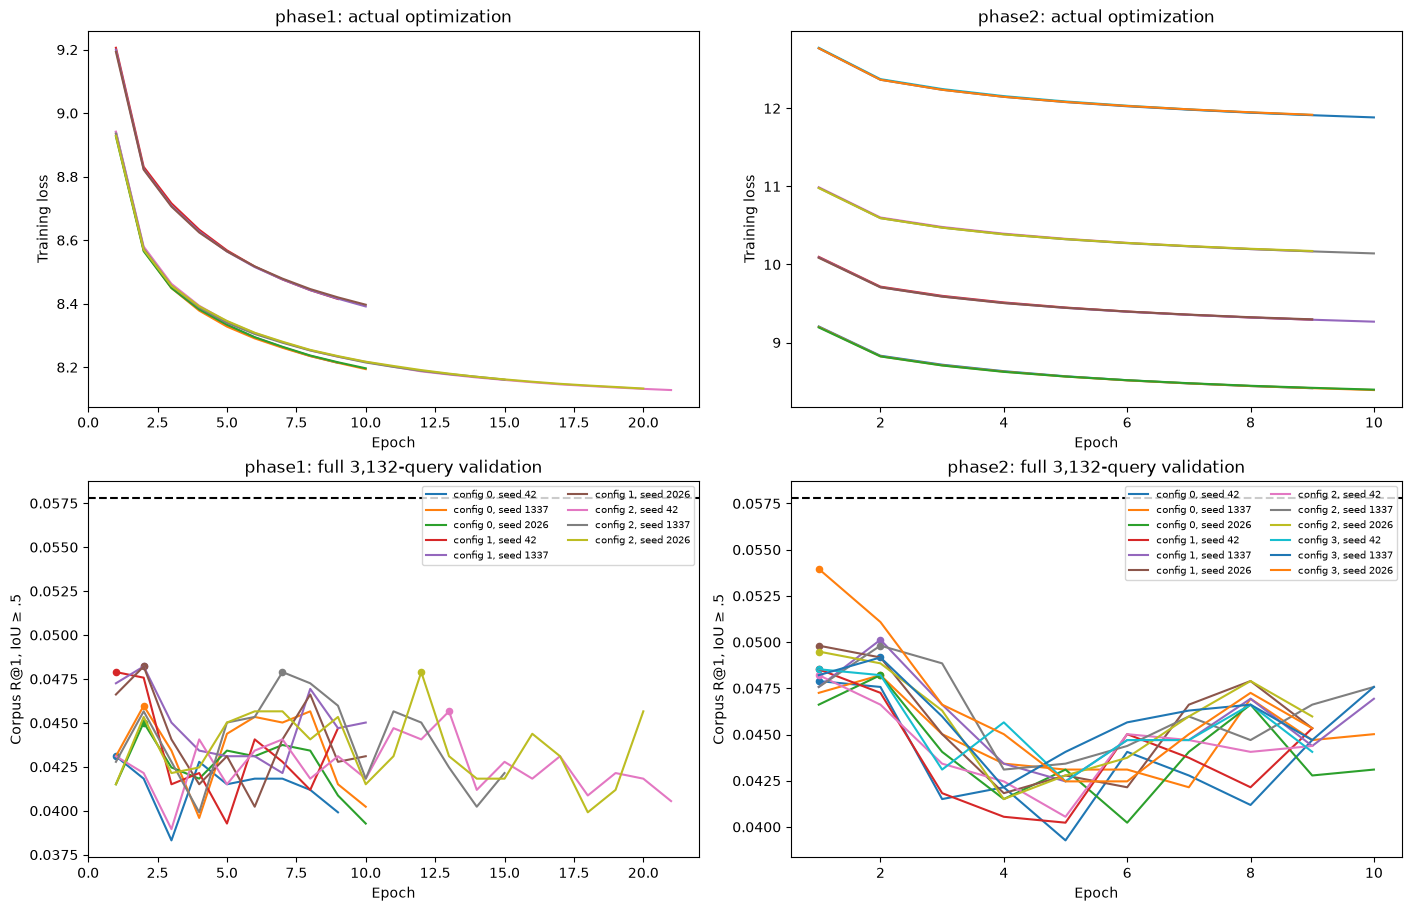

In [3]:
fig, axes = plt.subplots(2,2,figsize=(14,9),constrained_layout=True)
for col, phase in enumerate(('phase1','phase2')):
    for (config, seed), rows in history[history.phase==phase].groupby(['configuration','seed']):
        label=f'config {config}, seed {seed}'
        axes[0,col].plot(rows.epoch,rows.train_loss,label=label)
        axes[1,col].plot(rows.epoch,rows.validation_corpus_consensus_r1_iou50,label=label)
        best=int(fits[(fits.phase==phase)&(fits.configuration==config)&(fits.seed==seed)].best_epoch.iloc[0])
        best_row=rows[rows.epoch==best].iloc[0]
        axes[1,col].scatter([best],[best_row.validation_corpus_consensus_r1_iou50],s=20)
    axes[0,col].set(title=f'{phase}: actual optimization',xlabel='Epoch',ylabel='Training loss')
    axes[1,col].set(title=f'{phase}: full 3,132-query validation',xlabel='Epoch',ylabel='Corpus R@1, IoU ≥ .5')
    axes[1,col].axhline(REPORTS[phase]['baseline']['corpus_consensus_r1_iou50'],color='black',ls='--')
    axes[1,col].legend(fontsize=7,ncol=2)
plt.show()

,lambda,adapted_score_weight,promotion_eligible,validation.queries,validation.candidate_moments,validation.corpus_consensus_r1_iou50,validation.corpus_consensus_r5_iou50,validation.corpus_video_r1,validation.corpus_video_r5,validation.within_video_official_rank1,validation.within_video_official_rank5,validation.within_video_official_miou,validation.consensus_attainable_fraction,validation.metric_scope,validation.tie_rule
0,0.0,0.25,False,3132,15927,0.058110,0.124840,0.156769,0.215517,0.154853,0.431034,0.370262,1.0,licensed available subset; corpus metrics cust...,stable original candidate order; no gold-depen...
1,0.0,0.50,False,3132,15927,0.054598,0.122286,0.154534,0.212324,0.164751,0.450830,0.362023,1.0,licensed available subset; corpus metrics cust...,stable original candidate order; no gold-depen...
2,0.0,0.75,False,3132,15927,0.052363,0.116539,0.146552,0.204981,0.172095,0.476373,0.354965,1.0,licensed available subset; corpus metrics cust...,stable original candidate order; no gold-depen...
3,0.0,1.00,False,3132,15927,0.046935,0.112069,0.139527,0.198595,0.176564,0.484674,0.347201,1.0,licensed available subset; corpus metrics cust...,stable original candidate order; no gold-depen...
4,0.5,0.25,False,3132,15927,0.056194,0.125160,0.156130,0.216156,0.156130,0.428480,0.370266,1.0,licensed available subset; corpus metrics cust...,stable original candidate order; no gold-depen...
5,0.5,0.50,False,3132,15927,0.057471,0.122286,0.158046,0.215517,0.165390,0.455939,0.359976,1.0,licensed available subset; corpus metrics cust...,stable original candidate order; no gold-depen...
6,0.5,0.75,False,3132,15927,0.053640,0.118135,0.151660,0.207535,0.172095,0.477011,0.352547,1.0,licensed available subset; corpus metrics cust...,stable original candidate order; no gold-depen...
7,0.5,1.00,False,3132,15927,0.046935,0.114623,0.144955,0.201469,0.175607,0.491060,0.343960,1.0,licensed available subset; corpus metrics cust...,stable original candidate order; no gold-depen...
8,1.0,0.25,False,3132,15927,0.056513,0.125160,0.155811,0.215517,0.156130,0.429119,0.369922,1.0,licensed available subset; corpus metrics cust...,stable original candidate order; no gold-depen...
9,1.0,0.50,False,3132,15927,0.057791,0.122605,0.157727,0.214559,0.166667,0.458493,0.361280,1.0,licensed available subset; corpus metrics cust...,stable original candidate order; no gold-depen...


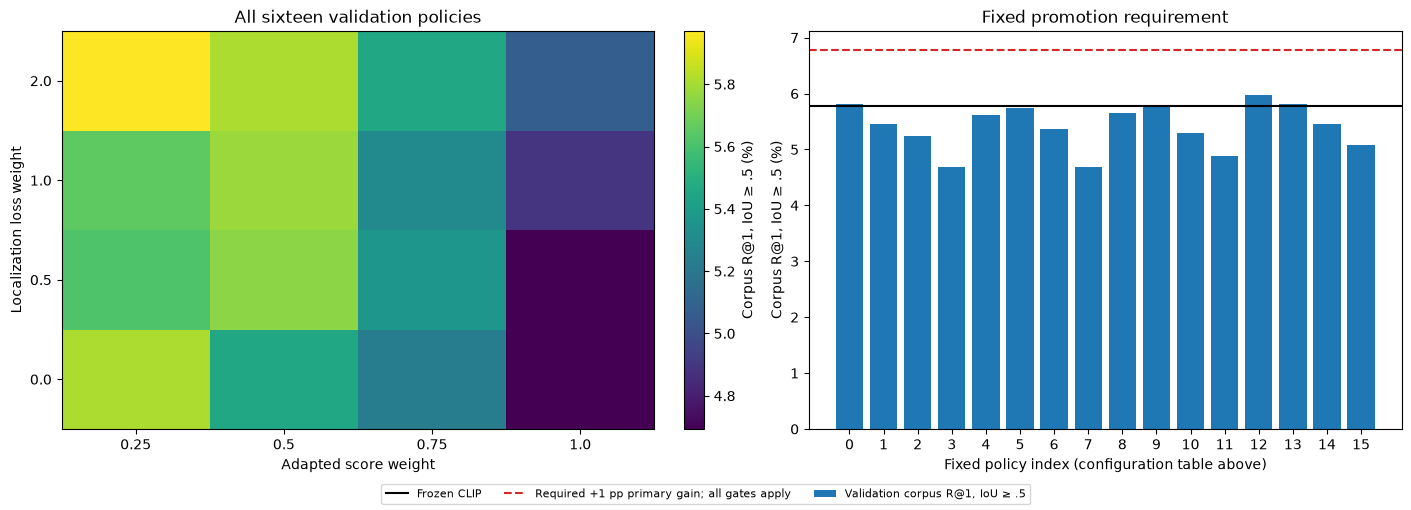

Frozen CLIP remains selected. A raw gain alone does not satisfy the fixed promotion rule.


In [4]:
policies=pd.json_normalize(REPORTS['phase2']['policies'])
assert len(policies)==16
display(policies)
metric='validation.corpus_consensus_r1_iou50'
fig,axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
pivot=policies.pivot(index='lambda',columns='adapted_score_weight',values=metric)
image=axes[0].imshow(pivot.to_numpy()*100,aspect='auto',origin='lower')
axes[0].set(xticks=range(len(pivot.columns)),xticklabels=pivot.columns,yticks=range(len(pivot.index)),yticklabels=pivot.index,xlabel='Adapted score weight',ylabel='Localization loss weight',title='All sixteen validation policies')
fig.colorbar(image,ax=axes[0],label='Corpus R@1, IoU ≥ .5 (%)')
values=[float(value)*100 for value in policies[metric]]
assert len(values)==16 and all(math.isfinite(value) and 0<=value<=100 for value in values)
bars=axes[1].bar(range(16),values,color='#1f77b4',label='Validation corpus R@1, IoU ≥ .5')
assert [bar.get_height() for bar in bars]==values
baseline=REPORTS['global']['selected_validation']['corpus_consensus_r1_iou50']
axes[1].axhline(baseline*100,color='black',label='Frozen CLIP')
axes[1].axhline((baseline+.01)*100,color='#d62728',ls='--',label='Required +1 pp primary gain; all gates apply')
axes[1].set(xticks=range(16),xlabel='Fixed policy index (configuration table above)',ylabel='Corpus R@1, IoU ≥ .5 (%)',title='Fixed promotion requirement')
handles,labels=axes[1].get_legend_handles_labels()
fig.legend(handles,labels,loc='outside lower center',ncol=3,fontsize=8)
plt.show()
assert not policies.promotion_eligible.any()
print('Frozen CLIP remains selected. A raw gain alone does not satisfy the fixed promotion rule.')

## Selected-policy validation errors
The per-query evidence belongs to the selected frozen policy; it does not invent predictions for rejected adapters.

,videos,candidates,bytes
split,,,
test,741,15039,3816057645
train,5916,119292,29550004957
val,797,15927,3753292268


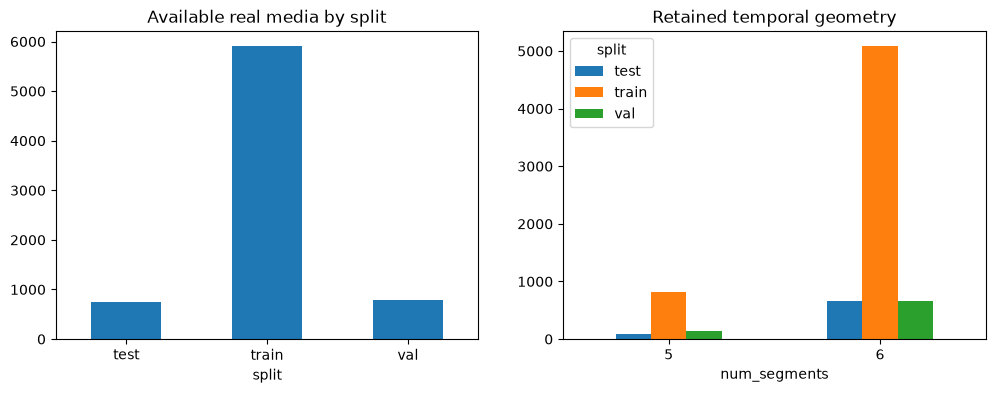

In [5]:
media = pd.DataFrame(artifact('media'))
train_queries = artifact('train_queries')
validation_queries = artifact('validation_queries')
prepared = artifact('prepared_manifest')
cache = artifact('cache_manifest')
assert len(media) == 7454 and len(train_queries) == 23202 and len(validation_queries) == 3132
assert not media.video.duplicated().any()
assert not media.sha256.duplicated().any(), 'Canonical hashes must remain disjoint'
assert media.num_segments.between(1,6).all()
media['candidates'] = media.num_segments * (media.num_segments + 1) // 2
coverage = media.groupby('split').agg(videos=('video','size'), candidates=('candidates','sum'), bytes=('bytes','sum'))
assert coverage.loc['val','candidates'] == 15927
assert coverage.loc['test','candidates'] == 15039
assert coverage.loc['test','videos'] == 741
display(coverage)
assert all(q['video'] in set(media.loc[media.split=='train','video']) for q in train_queries)
assert all(q['video'] in set(media.loc[media.split=='val','video']) for q in validation_queries)
fig, axes = plt.subplots(1,2,figsize=(12,4))
coverage.videos.plot.bar(ax=axes[0],title='Available real media by split',rot=0)
media.groupby(['split','num_segments']).size().unstack(0).plot.bar(ax=axes[1],title='Retained temporal geometry',rot=0)
plt.show()

"""Additive rank evidence for the unchanged, guarded one-shot evaluator.

Importing this module uses only the standard library. Native model operations
occur only in the explicitly invoked cloud release function.
"""

import hashlib
import json
import math
from pathlib import Path


def digest(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def _interval(value):
    if not isinstance(value, (list, tuple)) or len(value) != 2:
        raise ValueError("Inclusive start/end bins required")
    start, end = value
    if type(start) is not int or type(end) is not int or not 0 <= start <= end < 6:
        raise ValueError("Valid retained temporal bins required")
    return start, end


def _iou(prediction, reference):
    a, b = _interval(prediction)
    c, d = _interval(reference)
    return max(0, min(b, d) + 1 - max(a, c)) / (max(b, d) + 1 - min(a, c))


def _consensus(prediction, references):
    values = sorted(_iou(prediction, reference) for reference in references)
    if not values:
        raise ValueError("Actual human references required")
    selected = values[-3:]
    total = 0.0
    for value in selected:
        total += value
    return total / len(selected)


def replay_rank_evidence(candidates, rows, expected_queries, expected_ids=None):
    """Independently replay all eight metrics from saved finite ranks, no arrays."""
    if type(expected_queries) is not int or expected_queries <= 0 or not candidates:
        raise ValueError("Full nonempty cohort counts required")
    keys = [(row["video"], _interval(row["moment"])) for row in candidates]
    if len(keys) != len(set(keys)):
        raise ValueError("Unique canonical candidates required")
    by_video = {}
    for index, (video, _) in enumerate(keys):
        if not isinstance(video, str) or not video:
            raise ValueError("Actual canonical video required")
        by_video.setdefault(video, []).append(index)
    for indices in by_video.values():
        moments = [keys[index][1] for index in indices]
        segments = max(end for _, end in moments) + 1
        if moments != [
            (start, end) for start in range(segments) for end in range(start, segments)
        ]:
            raise ValueError("Complete original triangular candidate geometry required")
    totals = {
        name: []
        for name in (
            "corpus_consensus_r1_iou50",
            "corpus_consensus_r5_iou50",
            "corpus_video_r1",
            "corpus_video_r5",
            "within_video_official_rank1",
            "within_video_official_rank5",
            "within_video_official_miou",
            "consensus_attainable_fraction",
        )
    }
    ids = []
    for row in rows:
        query_id, video = row["id"], row["video"]
        if not isinstance(query_id, str) or not query_id or video not in by_video:
            raise ValueError("Full actual query identity required")
        ids.append(query_id)
        references = [_interval(value) for value in row["references"]]
        if not references:
            raise ValueError("Actual human references required")
        top = row["top5"]
        local = row["within_video_order"]
        if (
            len(top) != 5
            or len(local) != len(by_video[video])
            or len(local) != len(set(local))
            or set(local) != set(by_video[video])
        ):
            raise ValueError("Full unique within-video order and top five required")
        top_indices = [item["index"] for item in top]
        if len(top_indices) != len(set(top_indices)) or any(
            type(index) is not int or not 0 <= index < len(keys)
            for index in top_indices + local
        ):
            raise ValueError("Exact integer candidate indices required")
        values = [item["score"] for item in top]
        if any(
            type(value) not in (int, float) or not math.isfinite(value)
            for value in values
        ):
       

,validation,heldout
queries,3132.000000,2972.000000
candidate_moments,15927.000000,15039.000000
corpus_consensus_r1_iou50,0.057791,0.064939
corpus_consensus_r5_iou50,0.111430,0.129542
corpus_video_r1,0.143678,0.169246
corpus_video_r5,0.190294,0.216353
within_video_official_rank1,0.133461,0.127187
within_video_official_rank5,0.384738,0.349596
within_video_official_miou,0.367044,0.358313
consensus_attainable_fraction,1.000000,1.000000


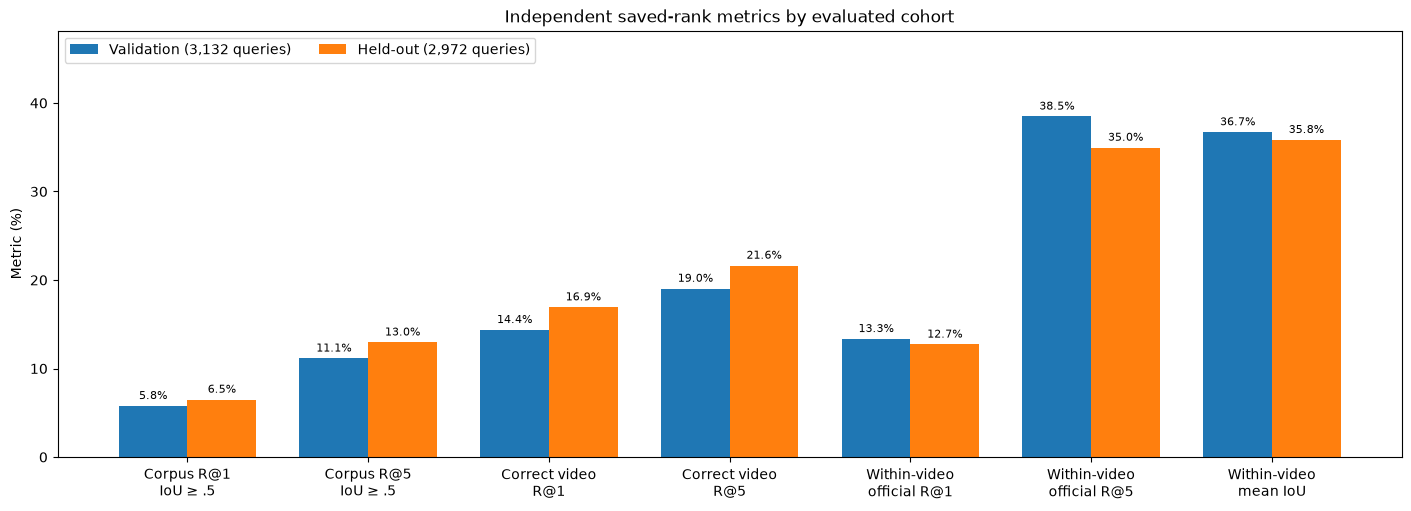

In [6]:
validation_candidates=artifact('validation_candidates')
validation_ranks=artifact('validation_ranks',lines=True)
test_candidates=artifact('test_candidates')
test_ranks=artifact('test_ranks',lines=True)
assert len(validation_candidates)==15927 and len(test_candidates)==15039
assert len(validation_ranks)==3132 and len(test_ranks)==2972
assert len({r['id'] for r in test_ranks})==2972
assert [r['id'] for r in validation_ranks]==[q['id'] for q in validation_queries]
for query,row in zip(validation_queries,validation_ranks):
    assert row['video']==query['video'] and row['references']==query['times']
show_source('src/models/release_evidence.py')
# Import the authenticated stdlib-only independent replay implementation.
import sys
sys.path.insert(0,str(PROJECT))
from src.models.release_evidence import replay_rank_evidence
import src.models.release_evidence as evidence_module
assert Path(evidence_module.__file__).resolve()==(PROJECT/'src/models/release_evidence.py').resolve()
validation_metrics=replay_rank_evidence(validation_candidates,validation_ranks,expected_queries=3132)
test_metrics=replay_rank_evidence(test_candidates,test_ranks,expected_queries=2972)
for key,value in validation_metrics.items():
    assert abs(value-REPORTS['global']['selected_validation'][key])<=1e-12
for key,value in test_metrics.items():
    assert abs(value-REPORTS['heldout']['selected'][key])<=1e-12
comparison=pd.DataFrame({'validation':validation_metrics,'heldout':test_metrics})
display(comparison)
metric_ids=['corpus_consensus_r1_iou50','corpus_consensus_r5_iou50','corpus_video_r1','corpus_video_r5','within_video_official_rank1','within_video_official_rank5','within_video_official_miou']
metric_labels=['Corpus R@1'+chr(10)+'IoU ≥ .5','Corpus R@5'+chr(10)+'IoU ≥ .5','Correct video'+chr(10)+'R@1','Correct video'+chr(10)+'R@5','Within-video'+chr(10)+'official R@1','Within-video'+chr(10)+'official R@5','Within-video'+chr(10)+'mean IoU']
for metrics in (validation_metrics,test_metrics):
    assert all(key in metrics and math.isfinite(float(metrics[key])) and 0<=float(metrics[key])<=1 for key in metric_ids)
validation_values=[float(validation_metrics[key])*100 for key in metric_ids]
heldout_values=[float(test_metrics[key])*100 for key in metric_ids]
positions=list(range(len(metric_ids)))
fig,ax=plt.subplots(figsize=(14,5),constrained_layout=True)
validation_bars=ax.bar([x-.19 for x in positions],validation_values,width=.38,color='#1f77b4',label='Validation (3,132 queries)')
heldout_bars=ax.bar([x+.19 for x in positions],heldout_values,width=.38,color='#ff7f0e',label='Held-out (2,972 queries)')
assert [bar.get_height() for bar in validation_bars]==validation_values
assert [bar.get_height() for bar in heldout_bars]==heldout_values
assert all(bar.get_facecolor()!=heldout_bars[0].get_facecolor() for bar in validation_bars)
ax.bar_label(validation_bars,fmt='%.1f%%',padding=3,fontsize=8)
ax.bar_label(heldout_bars,fmt='%.1f%%',padding=3,fontsize=8)
ax.set(xticks=positions,xticklabels=metric_labels,ylabel='Metric (%)',ylim=(0,min(100,max(validation_values+heldout_values)*1.2+2)),title='Independent saved-rank metrics by evaluated cohort')
ax.legend(loc='upper left',ncol=2)
plt.show()

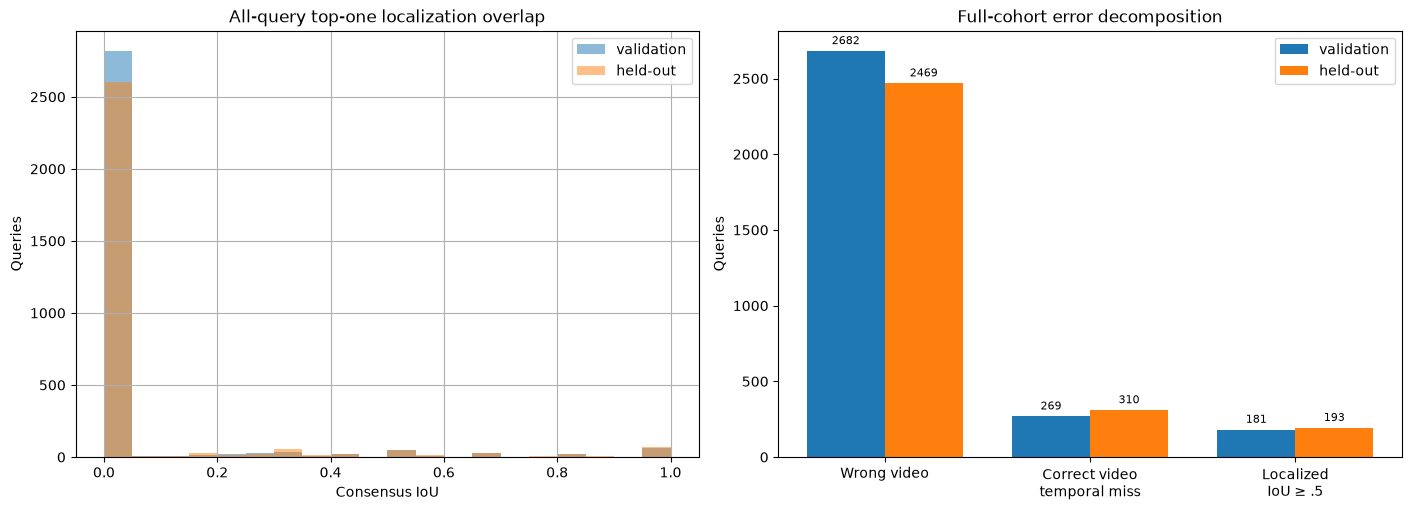

,queries,recall,video_recall
length_bucket,,,
"(0.0, 5.0]",880,0.054545,0.106818
"(5.0, 10.0]",1765,0.052691,0.149575
"(10.0, 15.0]",406,0.073892,0.192118
"(15.0, 25.0]",79,0.126582,0.177215
"(25.0, inf]",2,0.000000,0.000000


,query,predicted_video,actual_video,consensus_iou
0,the man in the hat briefly bends over the machine,24311648@N00_3081934824_e7cb9365ae.avi,35034348999@N01_6060447507_dc1a90b8ef.mov,0.0
1,screen turns on,68851855@N00_4261376098_dc90fa5eb4.mov,78946293@N00_3006650398_213f0476a2.mpg,0.0
2,camera pans over to shadow covering tv screen,22972235@N04_3483973442_914e5da898.avi,39727414@N00_4684305527_0bbf55d201.mp4,0.0
3,person gets out of seat and walks away,44124398982@N01_4464847559_c322a949ce.avi,68851855@N00_2650723731_b09c5645e8.mov,0.0
4,girl in all white jumping up and down,90994687@N00_2648116072_e1d5c3d973.avi,78658921@N00_7953510950_c532f66e82.mp4,0.0


Examples are actual validation queries. Held-out captions are not exported.


In [7]:
def iou(a,b):
    intersection=max(0,min(a[1],b[1])-max(a[0],b[0])+1)
    return intersection/((a[1]-a[0]+1)+(b[1]-b[0]+1)-intersection)
def error_frame(rows,candidates):
    records=[]
    for row in rows:
        predicted=candidates[row['top5'][0]['index']]
        overlaps=sorted(iou(predicted['moment'],ref) for ref in row['references'])[-3:]
        total=0.0
        for value in overlaps: total+=value
        overlap=total/len(overlaps) if predicted['video']==row['video'] else 0.0
        records.append(dict(id=row['id'],video=row['video'],predicted_video=predicted['video'],correct_video=predicted['video']==row['video'],consensus_iou=overlap,hit=overlap>=.5))
    return pd.DataFrame(records)
val_errors=error_frame(validation_ranks,validation_candidates)
test_errors=error_frame(test_ranks,test_candidates)
assert abs(int(val_errors.hit.sum())/len(val_errors)-validation_metrics['corpus_consensus_r1_iou50'])<=1e-12
assert abs(int(test_errors.hit.sum())/len(test_errors)-test_metrics['corpus_consensus_r1_iou50'])<=1e-12
fig,axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
categories=['Wrong video','Correct video'+chr(10)+'temporal miss','Localized'+chr(10)+'IoU ≥ .5']
positions=list(range(len(categories)))
for name,frame,color,offset in [('validation',val_errors,'#1f77b4',-.19),('held-out',test_errors,'#ff7f0e',.19)]:
    frame.consensus_iou.hist(bins=20,alpha=.5,color=color,ax=axes[0],label=name)
    counts=[int((~frame.correct_video).sum()),int((frame.correct_video&~frame.hit).sum()),int(frame.hit.sum())]
    assert sum(counts)==len(frame) and all(value>=0 for value in counts)
    bars=axes[1].bar([x+offset for x in positions],counts,width=.38,color=color,label=name)
    assert [bar.get_height() for bar in bars]==counts
    axes[1].bar_label(bars,fmt='%d',padding=3,fontsize=8)
axes[0].set(title='All-query top-one localization overlap',xlabel='Consensus IoU',ylabel='Queries');axes[0].legend()
axes[1].set(xticks=positions,xticklabels=categories,title='Full-cohort error decomposition',ylabel='Queries');axes[1].legend()
plt.show()
query_info=pd.DataFrame([dict(id=q['id'],words=len(q['text'].split())) for q in validation_queries])
length_errors=val_errors.merge(query_info,on='id',validate='one_to_one')
length_errors['length_bucket']=pd.cut(length_errors.words,[0,5,10,15,25,float('inf')])
display(length_errors.groupby('length_bucket',observed=True).agg(queries=('id','size'),recall=('hit','mean'),video_recall=('correct_video','mean')))
examples=length_errors.sort_values(['hit','consensus_iou','id']).head(5)
queries_by_id={q['id']:q for q in validation_queries}
display(pd.DataFrame([dict(query=queries_by_id[row.id]['text'],predicted_video=row.predicted_video,actual_video=row.video,consensus_iou=row.consensus_iou) for row in examples.itertuples()]))
print('Examples are actual validation queries. Held-out captions are not exported.')